### 1. Assess clustering methods 

In [1]:
import sys
import subprocess

expected = "/home/akash1/scgpt-cna/.venv-scgpt/bin/python"
print("Installing into:", sys.executable)
assert sys.executable == expected, "Select the scGPT kernel first."

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--no-deps",
        "igraph==0.11.9",
        "leidenalg==0.10.2",
        "texttable==1.7.0",
    ],
    check=True,
)

Installing into: /home/akash1/scgpt-cna/.venv-scgpt/bin/python


Looking in links: /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/x86-64-v4, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/x86-64-v3, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/generic, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/generic


CompletedProcess(args=['/home/akash1/scgpt-cna/.venv-scgpt/bin/python', '-m', 'pip', 'install', '--no-deps', 'igraph==0.11.9', 'leidenalg==0.10.2', 'texttable==1.7.0'], returncode=0)

In [2]:
import subprocess

python = "/home/akash1/scgpt-cna/.venv-scgpt/bin/python"

probe = """
import sys, site, os, importlib.util

print("Fresh Python:", sys.executable)
print("Environment prefix:", sys.prefix)
print("Site-packages:", site.getsitepackages())

for name in ["numpy", "scanpy", "igraph", "leidenalg", "texttable"]:
    spec = importlib.util.find_spec(name)
    print(name, "->", spec.origin if spec else "NOT FOUND")

for name in ["PIP_TARGET", "PIP_PREFIX", "PIP_USER"]:
    print(name, "=", os.environ.get(name))
"""

subprocess.run([python, "-c", probe], check=False)

print("\nPip installation locations:")
subprocess.run(
    [python, "-m", "pip", "show", "igraph", "leidenalg", "texttable"],
    check=False,
)

Fresh Python: /home/akash1/scgpt-cna/.venv-scgpt/bin/python
Environment prefix: /home/akash1/scgpt-cna/.venv-scgpt
Site-packages: ['/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages']
numpy -> /home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/numpy/__init__.py
scanpy -> /home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scanpy/__init__.py
igraph -> /home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/igraph/__init__.py
leidenalg -> /home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/leidenalg/__init__.py
texttable -> /home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/texttable.py
PIP_TARGET = None
PIP_PREFIX = /localscratch/akash1.28958258.0
PIP_USER = None

Pip installation locations:


Name: igraph
Version: 0.11.9
Summary: High performance graph data structures and algorithms
Home-page: https://igraph.org/python
Author: Tamas Nepusz
Author-email: ntamas@gmail.com
License: GNU General Public License (GPL)
Location: /home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages
Requires: texttable
Required-by: leidenalg
---
Name: leidenalg
Version: 0.10.2+computecanada
Summary: Leiden is a general algorithm for methods of community detection in large networks.
Home-page: 
Author: 
Author-email: "V.A. Traag" <vincent@traag.net>
License: 
Location: /home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages
Requires: igraph
Required-by: scgpt
---
Name: texttable
Version: 1.7.0+computecanada
Summary: module to create simple ASCII tables
Home-page: https://github.com/foutaise/texttable/
Author: Gerome Fournier
Author-email: jef@foutaise.org
License: 
Location: /home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages
Requires: 
Required-by: igraph


CompletedProcess(args=['/home/akash1/scgpt-cna/.venv-scgpt/bin/python', '-m', 'pip', 'show', 'igraph', 'leidenalg', 'texttable'], returncode=0)

In [3]:
import os
import subprocess

python = "/home/akash1/scgpt-cna/.venv-scgpt/bin/python"

install_env = os.environ.copy()
install_env.pop("PIP_PREFIX", None)

subprocess.run(
    [
        python, "-m", "pip", "install",
        "--no-deps",
        "igraph==0.11.9",
        "leidenalg==0.10.2",
        "texttable==1.7.0",
    ],
    env=install_env,
    check=True,
)

# Verify in a fresh Python process.
subprocess.run(
    [
        python, "-c",
        "import igraph, leidenalg, texttable; "
        "print('igraph:', igraph.__file__); "
        "print('leidenalg:', leidenalg.__file__); "
        "print('All imports succeeded')",
    ],
    check=True,
)

Looking in links: /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/x86-64-v4, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/x86-64-v3, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/generic, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/generic
igraph: /home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/igraph/__init__.py
leidenalg: /home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/leidenalg/__init__.py
All imports succeeded


CompletedProcess(args=['/home/akash1/scgpt-cna/.venv-scgpt/bin/python', '-c', "import igraph, leidenalg, texttable; print('igraph:', igraph.__file__); print('leidenalg:', leidenalg.__file__); print('All imports succeeded')"], returncode=0)

In [4]:
import sys
import numpy
import scipy
import scanpy
import anndata
import igraph
import leidenalg
from importlib.metadata import version

print("Python:", sys.executable)

for package in [
    "numpy", "scipy", "scanpy", "anndata",
    "igraph", "leidenalg", "texttable",
]:
    print(package, version(package))

Python: /home/akash1/scgpt-cna/.venv-scgpt/bin/python
numpy 1.26.4+computecanada
scipy 1.12.0+computecanada
scanpy 1.10.4
anndata 0.10.9
igraph 0.11.9
leidenalg 0.10.2+computecanada
texttable 1.7.0+computecanada


In [5]:
# 1 — Configuration. Run Census first; later switch SOURCE to 'LAB'.
from pathlib import Path
from datetime import datetime, timezone
import gc,gzip,hashlib,importlib.metadata,json,sys,time
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.io import mmread
from scipy.stats import spearmanr
import anndata as ad
import scanpy as sc
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score,adjusted_mutual_info_score,silhouette_score
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from IPython.display import display
# If packages are missing, install in a separate clustering venv/kernel rather than upgrading inference dependencies:
# python -m pip install 'scanpy>=1.10,<1.12' 'anndata<0.12' 'igraph>=0.11,<0.12' 'leidenalg>=0.10,<0.11'
import igraph,leidenalg
ROOT=Path.home()/'scgpt-cna'
SOURCE='LAB'  # Then LAB; rerun from cell 1 to create a separate run.
CENSUS_DATA=ROOT/'sanity_check/data/census_proximal_tubule_256/reference_raw.h5ad'
# Lab paths are recovered from your completed report benchmark; no ambiguous matrix search.
BENCHMARK_RUN=None
LAB_SAMPLE_IDS=['C3N-00148-01','C3N-01798-01']  # Kidney, brain; later extend to the other benchmark specimens.
SEED=42
PANEL_SALT='honours-clustering-panels-v1'
MIN_UMI=200; MIN_GENES=100
# Modest count/gene eligibility filters; no automatic mitochondrial or malignancy filtering.
MIN_PANEL_CELLS=3
N_HVG=2000;N_PCS=30;N_NEIGHBORS=15
LEIDEN_RESOLUTIONS=[0.25,0.5,1.0]
STABILITY_SEEDS=[101,102,103,104,105]
SUBSAMPLE_FRACTION=0.8
MAX_VALIDATION_GENES=2000
MAX_COHERENCE_ANCHORS=2000
PARTNERS_PER_ANCHOR=10
POOL_SIZES=[1,5,10]
TARGET_POOLS_PER_PARTITION=32
MAKE_UMAP=True
N_THREADS=4
assert SOURCE in {'CENSUS','LAB'}
assert 0<SUBSAMPLE_FRACTION<1
RUN_DIR=ROOT/'clustering_analysis/results'/(datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')+'_'+SOURCE.lower())
RUN_DIR.mkdir(parents=True,exist_ok=False)
sc.settings.n_jobs=N_THREADS

def digest(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024**2),b''):h.update(block)
    return h.hexdigest()

def seed_for(*parts):return int(hashlib.sha256('|'.join(map(str,parts)).encode()).hexdigest()[:8],16)
def base_id(x):
    import re
    return re.sub(r'\.\d+$','',str(x))  # Preserve distinct PAR_Y identities.
def gene_panel(x):
    p=seed_for(PANEL_SALT,base_id(x))%100
    return 'clustering' if p<60 else ('validation' if p<80 else 'prediction_reserved')

settings={k:globals()[k] for k in ['SOURCE','SEED','PANEL_SALT','MIN_UMI','MIN_GENES','MIN_PANEL_CELLS','N_HVG','N_PCS',
    'N_NEIGHBORS','LEIDEN_RESOLUTIONS','STABILITY_SEEDS','SUBSAMPLE_FRACTION','MAX_VALIDATION_GENES',
    'MAX_COHERENCE_ANCHORS','PARTNERS_PER_ANCHOR','POOL_SIZES','TARGET_POOLS_PER_PARTITION','MAKE_UMAP']}
settings.update(python=sys.version,versions={p:importlib.metadata.version(p) for p in ['scanpy','anndata','numpy','pandas','scipy','scikit-learn','igraph','leidenalg']},
    analysis='Exploratory grouping; no biological ground truth; stability conditional on fixed representation',
    panel_use='Only clustering panel may inform grouping; validation scores inform method choice; reserve prediction panel')
(RUN_DIR/'configuration.json').write_text(json.dumps(settings,indent=2))
print('Output:',RUN_DIR)
print('CPU-only; reference/evaluation source roles will be frozen before clustering.')

Output: /home/akash1/scgpt-cna/clustering_analysis/results/20261128T174241268446Z_lab
CPU-only; reference/evaluation source roles will be frozen before clustering.


In [6]:
# 2 — Explicit input inventory. Census is local; lab sources come from the completed benchmark.
if SOURCE=='CENSUS':
    assert CENSUS_DATA.is_file(),CENSUS_DATA
    inventory=pd.DataFrame([dict(sample_id='CENSUS_PROXIMAL_TUBULE_256',case_id='not_applicable',
        source='Census',primary_site='Kidney',diagnosis='Census-annotated proximal-tubule cohort',source_h5ad=str(CENSUS_DATA))])
else:
    if BENCHMARK_RUN is None:
        pointer=ROOT/'report_benchmark/results/latest_full_run.json'
        BENCHMARK_RUN=Path(json.loads(pointer.read_text())['run_dir'])
    BENCHMARK_RUN=Path(BENCHMARK_RUN)
    prior=pd.read_csv(BENCHMARK_RUN/'evaluation_units.tsv',sep='\t',keep_default_na=False)
    assert prior.sample_id.is_unique and set(LAB_SAMPLE_IDS).issubset(prior.sample_id)
    inventory=prior.set_index('sample_id').loc[LAB_SAMPLE_IDS].reset_index()
    assert inventory.source.str.lower().eq('lab').all()
    assert inventory.case_id.is_unique,'For this comparison choose one specimen per patient.'
    inventory['diagnosis']=inventory['diagnoses.0.primary_diagnosis']
    for r in inventory.to_dict('records'):
        audit=json.loads((BENCHMARK_RUN/r['sample_id']/'sample_audit.json').read_text())
        for entry in audit['source_files']:
            assert Path(entry['path']).is_file()
            assert digest(entry['path'])==entry['sha256'],f"Changed benchmark source: {entry['path']}"
inventory.to_csv(RUN_DIR/'input_inventory.tsv',sep='\t',index=False)
display(inventory[['sample_id','case_id','source','primary_site','diagnosis']])

,sample_id,case_id,source,primary_site,diagnosis
0,C3N-00148-01,C3N-00148,Lab,Kidney,"Renal cell carcinoma, NOS"
1,C3N-01798-01,C3N-01798,Lab,Brain,Glioblastoma


In [7]:
# 3 — Sparse loaders and independent panel preprocessing.
def load_unit(record):
    paths=[]
    if record['source']=='Census':
        a=ad.read_h5ad(record['source_h5ad'])
        assert 'counts' in a.layers,'Need the original raw-count layer.'
        X=sparse.csr_matrix(a.layers['counts']).copy()
        obs=a.obs.copy().reset_index(drop=True)
        assert 'soma_joinid' in obs and obs.soma_joinid.is_unique
        assert {'donor_id','dataset_id'}.issubset(obs)
        obs['cell_id']=record['sample_id']+':'+obs.soma_joinid.astype(str)
        var=pd.DataFrame({'gene_id':a.var['feature_id'].astype(str).to_numpy(),
                          'gene_symbol':a.var['feature_name'].astype(str).to_numpy()})
        paths=[record['source_h5ad']]
    else:
        f=pd.read_csv(record['features_file'],sep='\t',header=None,dtype=str)
        bc=pd.read_csv(record['barcodes_file'],sep='\t',header=None,dtype=str)[0]
        assert bc.is_unique and f.shape[1]>=3
        path=Path(record['matrix_file'])
        with threadpool_limits(limits=N_THREADS):
            if path.suffix=='.gz':
                with gzip.open(path,'rb') as stream:X=mmread(stream).T.tocsr()
            else:X=mmread(path).T.tocsr()
        assert X.shape==(len(bc),len(f))
        keep=f[2].eq('Gene Expression').to_numpy();X=X[:,keep].tocsr()
        var=pd.DataFrame({'gene_id':f.loc[keep,0].to_numpy(),'gene_symbol':f.loc[keep,1].to_numpy()})
        obs=pd.DataFrame({'barcode':bc,'cell_id':record['sample_id']+':'+bc,
                          'donor_id':str(record['case_id']),'dataset_id':str(record['sample_id'])})
        paths=[record[k] for k in ['matrix_file','barcodes_file','features_file']]
    X.sum_duplicates();X.eliminate_zeros();X.sort_indices()
    assert np.isfinite(X.data).all() and (X.data>=0).all()
    assert np.equal(X.data,np.rint(X.data)).all(),'Expected integer raw UMI counts.'
    assert var.gene_id.is_unique and obs.cell_id.is_unique
    assert obs[['donor_id','dataset_id']].notna().all().all(),'Donor/dataset identity is required for pooling.'
    obs['sample_id']=record['sample_id'];obs['case_id']=record['case_id']
    obs['tissue']=record['primary_site'];obs['diagnosis']=record['diagnosis']
    obs['source_row']=np.arange(len(obs))
    obs['total_counts']=np.asarray(X.sum(axis=1)).ravel()
    obs['detected_genes']=X.getnnz(axis=1)
    mt=var.gene_symbol.str.upper().str.startswith('MT-').to_numpy()
    obs['pct_counts_mt']=100*np.asarray(X[:,mt].sum(axis=1)).ravel()/np.maximum(obs.total_counts,1)
    obs['eligible']=obs.total_counts.ge(MIN_UMI)&obs.detected_genes.ge(MIN_GENES)
    # Optional annotations are descriptive only. No inferred malignancy labels are manufactured.
    if 'cell_type' not in obs:obs['cell_type']='unassigned'
    obs['pooling_block']=obs.donor_id.astype(str)+'|'+obs.dataset_id.astype(str)
    obs['partition']='excluded'
    # Split source cells within donor/dataset; independent of clustering or validation scores.
    for block,indices in obs.loc[obs.eligible].groupby('pooling_block',sort=True).groups.items():
        order=np.random.default_rng(seed_for(SEED,record['sample_id'],block,'split')).permutation(indices)
        obs.loc[order[:len(order)//2],'partition']='reference'
        obs.loc[order[len(order)//2:],'partition']='evaluation'
    var['base_gene_id']=var.gene_id.map(base_id)
    var['panel']=var.base_gene_id.map(gene_panel)
    var['mitochondrial']=mt
    audit=dict(n_source_cells=len(obs),n_eligible_cells=int(obs.eligible.sum()),n_features=X.shape[1],
        sources=[dict(path=str(p),sha256=digest(p)) for p in paths])
    return X,obs,var,audit

def panel_view(X,columns):
    # Normalize WITHIN each panel: validation/prediction counts cannot influence clustering size factors.
    out=X[:,columns].tocsr().astype(np.float32)
    total=np.asarray(out.sum(axis=1)).ravel()
    out=sparse.diags(1e4/np.maximum(total,1)).dot(out).tocsr()
    out.data=np.log1p(out.data)
    return out

def representation(X,obs,var):
    expressed=np.asarray((X>0).sum(axis=0)).ravel()>=MIN_PANEL_CELLS
    cc=np.flatnonzero(var.panel.eq('clustering').to_numpy()&~var.mitochondrial.to_numpy()&expressed)
    vc=np.flatnonzero(var.panel.eq('validation').to_numpy()&~var.mitochondrial.to_numpy()&expressed)
    vc=np.array(sorted(vc,key=lambda i:seed_for('validation_features',var.iloc[i].base_gene_id))[:MAX_VALIDATION_GENES],dtype=int)
    assert len(cc)>=20 and len(vc)>=10,'Too few expressed genes for meaningful panel comparisons.'
    C=panel_view(X,cc)
    good=np.asarray(C.sum(axis=1)).ravel()>0
    assert good.all(),'Some cells have zero clustering-panel counts; adjust eligibility explicitly.'
    a=ad.AnnData(C)
    sc.pp.highly_variable_genes(a,flavor='seurat',n_top_genes=min(N_HVG,len(cc)),subset=False)
    hvg=np.flatnonzero(a.var.highly_variable.to_numpy())
    assert len(hvg)>=10
    assert len(obs)*len(hvg)*np.dtype(np.float32).itemsize<2*1024**3,'Clustering feature matrix would exceed 2 GiB; reduce N_HVG or process smaller units.'
    dense=C[:,hvg].toarray()
    assert dense.nbytes<2*1024**3,'Clustering feature matrix would exceed 2 GiB; reduce N_HVG or process smaller units.'
    mu=dense.mean(axis=0);sd=dense.std(axis=0);sd[sd<1e-8]=1
    Z=np.clip((dense-mu)/sd,-10,10)
    npc=min(N_PCS,Z.shape[0]-1,Z.shape[1]-1)
    pca=PCA(n_components=npc,svd_solver='randomized',random_state=SEED)
    with threadpool_limits(limits=N_THREADS):P=pca.fit_transform(Z)
    V=panel_view(X,vc)
    V=normalize(V,norm='l2',axis=1,copy=False).tocsr()
    var=var.copy();var['used_for_clustering']=False;var.loc[cc[hvg],'used_for_clustering']=True
    var['used_for_validation']=False;var.loc[vc,'used_for_validation']=True
    assert not var.loc[var.used_for_clustering,'panel'].isin(['validation','prediction_reserved']).any()
    assert not var.loc[var.used_for_validation,'panel'].eq('prediction_reserved').any()
    artifacts=dict(pca_mean=pca.mean_,pca_components=pca.components_,explained_variance_ratio=pca.explained_variance_ratio_,
                   log_gene_mean=mu,log_gene_std=sd,hvg_columns=cc[hvg])
    return np.asarray(P,dtype=np.float32),V,var,artifacts

def neighbor_graph(P,seed):
    a=ad.AnnData(np.zeros((len(P),1),dtype=np.float32))
    a.obsm['X_pca']=P
    sc.pp.neighbors(a,n_neighbors=min(N_NEIGHBORS,len(P)-1),use_rep='X_pca',random_state=seed)
    return a

def leiden_labels(graph,resolution,seed):
    sc.tl.leiden(graph,resolution=resolution,random_state=seed,directed=False,
                 flavor='leidenalg',n_iterations=-1,key_added='candidate')
    return graph.obs.candidate.astype(str).to_numpy()

def fit_candidate(P,candidate,seed,graph=None):
    if candidate['method']=='one_group':return np.repeat('0',len(P))
    if candidate['method']=='leiden':return leiden_labels(graph if graph is not None else neighbor_graph(P,seed),candidate['resolution'],seed)
    with threadpool_limits(limits=N_THREADS):
        return KMeans(n_clusters=int(candidate['k']),random_state=seed,n_init=10).fit_predict(P).astype(str)
print('Loaders and gene-panel-restricted representations ready.')

Loaders and gene-panel-restricted representations ready.


In [8]:
# 4 — Quality measures. These never train the clustering representation on held-out genes.
def add_depth_strata(obs):
    obs=obs.copy();obs['depth_bin']='all'
    for _,ix in obs.groupby('pooling_block',sort=True).groups.items():
        if len(ix)>=16:
            obs.loc[ix,'depth_bin']=pd.qcut(obs.loc[ix,'total_counts'].rank(method='first'),4,labels=False).astype(str)
    obs['match_block']=obs.pooling_block.astype(str)+'|depth='+obs.depth_bin.astype(str)
    return obs

def coherence(V,obs,labels,seed):
    rng=np.random.default_rng(seed)
    nonzero=np.asarray(V.getnnz(axis=1))>0
    blocks=obs.match_block.to_numpy();labels=np.asarray(labels)
    anchors=np.flatnonzero(nonzero)
    if len(anchors)>MAX_COHERENCE_ANCHORS:anchors=np.sort(rng.choice(anchors,MAX_COHERENCE_ANCHORS,replace=False))
    rows=[]
    byblock={b:np.flatnonzero((blocks==b)&nonzero) for b in np.unique(blocks)}
    for i in anchors:
        control=byblock[blocks[i]];control=control[control!=i]
        same=control[labels[control]==labels[i]]
        if not len(same) or not len(control):continue
        a=rng.choice(same,PARTNERS_PER_ANCHOR,replace=True)
        b=rng.choice(control,PARTNERS_PER_ANCHOR,replace=True)
        if np.array_equal(same,control):a=b.copy()  # Exactly zero for the single-group control.
        within=np.asarray(V[a].multiply(V[i]).sum(axis=1)).ravel().mean()
        random=np.asarray(V[b].multiply(V[i]).sum(axis=1)).ravel().mean()
        rows.append(dict(cell_id=obs.iloc[i].cell_id,cluster=labels[i],within_cosine=within,random_cosine=random,gain=within-random))
    frame=pd.DataFrame(rows,columns=['cell_id','cluster','within_cosine','random_cosine','gain'])
    return frame,dict(n_coherence_anchors=len(frame),coherence_anchor_coverage=len(frame)/max(len(anchors),1),
        mean_validation_cosine_gain=float(frame.gain.mean()) if len(frame) else np.nan,
        median_validation_cosine_gain=float(frame.gain.median()) if len(frame) else np.nan)

def capacities(obs,labels):
    z=obs[['pooling_block','donor_id','dataset_id','partition']].copy();z['cluster']=labels
    counts=z.groupby(['pooling_block','donor_id','dataset_id','cluster','partition'],observed=True).size().unstack('partition',fill_value=0)
    for name in ['reference','evaluation']:
        if name not in counts:counts[name]=0
    counts=counts.reset_index();rows=[]
    for r in counts.to_dict('records'):
        for k in POOL_SIZES:
            nr=int(r['reference'])//k;ne=int(r['evaluation'])//k
            rows.append({**r,'pool_size':k,'n_reference_pools':nr,'n_evaluation_pools':ne,
                         'matched_pool_capacity':min(nr,ne),'supports_target':min(nr,ne)>=TARGET_POOLS_PER_PARTITION})
    return pd.DataFrame(rows)

def associations(labels,values):
    return float(adjusted_mutual_info_score(labels,np.asarray(values).astype(str))) if pd.Series(values).nunique()>1 else np.nan

def measure(P,V,obs,labels,candidate):
    counts=pd.Series(labels).value_counts();n=len(obs);k=len(counts)
    sil=float(silhouette_score(P,labels,sample_size=min(2000,n),random_state=SEED)) if 1<k<n else np.nan
    coh,stats=coherence(V,obs,labels,seed_for(SEED,'coherence'))
    cap=capacities(obs,labels)
    qc=obs.assign(cluster=labels).groupby('cluster',observed=True).agg(n_cells=('cell_id','size'),median_counts=('total_counts','median'),
        median_genes=('detected_genes','median'),median_pct_mt=('pct_counts_mt','median'))
    largest=cap.loc[cap.pool_size.eq(max(POOL_SIZES))]
    metrics={**candidate,'n_clusters':k,'min_cluster_cells':int(counts.min()),'max_cluster_cells':int(counts.max()),
        'fraction_cells_in_clusters_under_20':float(counts[counts<20].sum()/n),'silhouette_PCA':sil,
        'donor_AMI':associations(labels,obs.donor_id),'depth_AMI':associations(labels,obs.depth_bin),**stats,
        'max_matched_pools_at_largest_size':int(largest.matched_pool_capacity.max()),
        'n_strata_supporting_target_at_largest_size':int(largest.supports_target.sum())}
    return metrics,coh,cap,qc
print('Quality metrics ready; donor/depth matched validation partners and exact split-aware pool capacities.')

Quality metrics ready; donor/depth matched validation partners and exact split-aware pool capacities.


In [ ]:
# 5 — Run the comparison. No winner is selected automatically.
all_metrics=[];all_stability=[];all_capacities=[];all_labels=[];all_coherence=[]
for record in inventory.to_dict('records'):
    sid=record['sample_id'];out=RUN_DIR/sid;out.mkdir(exist_ok=True)
    print('Loading',sid,flush=True)
    X,full_obs,var,audit=load_unit(record)
    full_obs.to_csv(out/'source_cells_and_eligibility.tsv',sep='\t',index=False)
    use=np.flatnonzero(full_obs.eligible.to_numpy())
    assert len(use)>=30,'Too few eligible cells; do not force clustering.'
    obs=full_obs.iloc[use].reset_index(drop=True);obs=add_depth_strata(obs)
    X=X[use].tocsr()
    P,V,var,artifacts=representation(X,obs,var)
    del X;gc.collect()
    np.save(out/'X_pca.npy',P);sparse.save_npz(out/'validation_log_l2.npz',V)
    np.savez_compressed(out/'pca_parameters.npz',**artifacts)
    var.to_csv(out/'gene_panels_and_features.tsv',sep='\t',index=False)
    graph=neighbor_graph(P,SEED)
    candidates=[dict(candidate='one_group',method='one_group',resolution=np.nan,k=1)]
    labels_by={'one_group':np.repeat('0',len(obs))};matched=[]
    for res in LEIDEN_RESOLUTIONS:
        name=f'leiden_r{res:g}';labels=leiden_labels(graph,res,SEED);k=len(set(labels))
        candidates.append(dict(candidate=name,method='leiden',resolution=res,k=k));labels_by[name]=labels
        matched.append(dict(leiden_candidate=name,matched_kmeans=f'kmeans_k{k}' if k>1 else 'one_group',n_clusters=k))
    for k in sorted({int(c['k']) for c in candidates if c['method']=='leiden'}):
        if k>1:
            c=dict(candidate=f'kmeans_k{k}',method='kmeans',resolution=np.nan,k=k)
            candidates.append(c);labels_by[c['candidate']]=fit_candidate(P,c,SEED)
    pd.DataFrame(matched).to_csv(out/'matched_cluster_counts.csv',index=False)
    pd.DataFrame(candidates).to_csv(out/'candidate_configuration.csv',index=False)
    for c in candidates:
        name=c['candidate'];labels=labels_by[name]
        metrics,coh,cap,qc=measure(P,V,obs,labels,c)
        all_metrics.append(dict(sample_id=sid,tissue=record['primary_site'],diagnosis=record['diagnosis'],**metrics))
        coh['sample_id']=sid;coh['candidate']=name;all_coherence.append(coh)
        cap['sample_id']=sid;cap['candidate']=name;all_capacities.append(cap)
        qc.to_csv(out/f'cluster_QC_{name}.csv')
        obs[name]=labels
        print(sid,name,'clusters:',len(set(labels)),'validation gain:',round(metrics['mean_validation_cosine_gain'],4),flush=True)
    # Seed and 80%-cell perturbation combined. Representation remains fixed: do not call this whole-pipeline stability.
    for repeat in STABILITY_SEEDS:
        keep=np.sort(np.random.default_rng(seed_for(SEED,sid,repeat,'subsample')).choice(len(obs),max(20,int(SUBSAMPLE_FRACTION*len(obs))),replace=False))
        subgraph=neighbor_graph(P[keep],repeat)
        for c in candidates:
            if c['method']=='one_group':continue  # A single cluster is trivially stable, not evidence of biology.
            if c['k']>=len(keep):continue
            lab=fit_candidate(P[keep],c,repeat,subgraph)
            all_stability.append(dict(sample_id=sid,candidate=c['candidate'],repeat_seed=repeat,n_subsampled=len(keep),
                n_clusters_subsample=len(set(lab)),ARI=adjusted_rand_score(labels_by[c['candidate']][keep],lab)))
        print(sid,'stability repeat',repeat,'done',flush=True)
    # Visualization embedding uses clustering genes only. Never cluster the 2-D UMAP.
    if MAKE_UMAP:
        sc.tl.umap(graph,random_state=SEED)
        obs['UMAP_1']=graph.obsm['X_umap'][:,0];obs['UMAP_2']=graph.obsm['X_umap'][:,1]
    else:
        obs['UMAP_1']=np.nan;obs['UMAP_2']=np.nan
    obs['PC1']=P[:,0];obs['PC2']=P[:,1]
    obs.to_csv(out/'cell_metadata_and_candidate_labels.tsv',sep='\t',index=False)
    all_labels.append(obs)
    audit.update(sample_id=sid,representation='Panel-specific CP10k/log1p; clustering-panel HVGs; z-score clip +/-10; PCA',
        n_HVG=int(var.used_for_clustering.sum()),n_validation_genes=int(var.used_for_validation.sum()),
        n_reserved_prediction_features=int(var.panel.eq('prediction_reserved').sum()),
        reference_evaluation='Frozen within donor+dataset before clustering; clustering itself transductive on clustering genes only')
    (out/'source_and_preprocessing.json').write_text(json.dumps(audit,indent=2))
    del P,V,graph;gc.collect()
metrics=pd.DataFrame(all_metrics);stability=pd.DataFrame(all_stability,columns=['sample_id','candidate','repeat_seed','n_subsampled','n_clusters_subsample','ARI'])
if len(stability):
    st=stability.groupby(['sample_id','candidate'],as_index=False).agg(mean_stability_ARI=('ARI','mean'),min_stability_ARI=('ARI','min'),n_repeats=('ARI','size'))
    metrics=metrics.merge(st,on=['sample_id','candidate'],how='left',validate='one_to_one')
else:
    metrics['mean_stability_ARI']=np.nan;metrics['min_stability_ARI']=np.nan;metrics['n_repeats']=0
metrics['stability_heuristic_pass']=metrics.mean_stability_ARI.ge(.75)
metrics['positive_validation_gain']=metrics.mean_validation_cosine_gain.gt(0)
for name,frame in [('candidate_metrics',metrics),('stability_repeats',stability),('pool_capacities',pd.concat(all_capacities,ignore_index=True)),
                   ('coherence_by_anchor',pd.concat(all_coherence,ignore_index=True)),('all_cell_labels',pd.concat(all_labels,ignore_index=True))]:
    frame.to_csv(RUN_DIR/f'{name}.csv',index=False)
(RUN_DIR/'completed.json').write_text(json.dumps(dict(complete=True),indent=2))
print('Complete. Do not interpret small positive coherence gains or ARI alone as verified cell types.')
display(metrics.round(3))

Loading C3N-00148-01


/tmp/ipykernel_2743260/1363948205.py:105: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(graph,resolution=resolution,random_state=seed,directed=False,


C3N-00148-01 one_group clusters: 1 validation gain: 0.0
C3N-00148-01 leiden_r0.25 clusters: 10 validation gain: 0.052
C3N-00148-01 leiden_r0.5 clusters: 11 validation gain: 0.0543
C3N-00148-01 leiden_r1 clusters: 17 validation gain: 0.0571
C3N-00148-01 kmeans_k10 clusters: 10 validation gain: 0.0512
C3N-00148-01 kmeans_k11 clusters: 11 validation gain: 0.0478
C3N-00148-01 kmeans_k17 clusters: 17 validation gain: 0.0538
C3N-00148-01 stability repeat 101 done
C3N-00148-01 stability repeat 102 done
C3N-00148-01 stability repeat 103 done
C3N-00148-01 stability repeat 104 done
C3N-00148-01 stability repeat 105 done
Loading C3N-01798-01
C3N-01798-01 one_group clusters: 1 validation gain: 0.0
C3N-01798-01 leiden_r0.25 clusters: 11 validation gain: 0.0474
C3N-01798-01 leiden_r0.5 clusters: 14 validation gain: 0.0497
C3N-01798-01 leiden_r1 clusters: 20 validation gain: 0.0516
C3N-01798-01 kmeans_k11 clusters: 11 validation gain: 0.0476
C3N-01798-01 kmeans_k14 clusters: 14 validation gain: 0.048

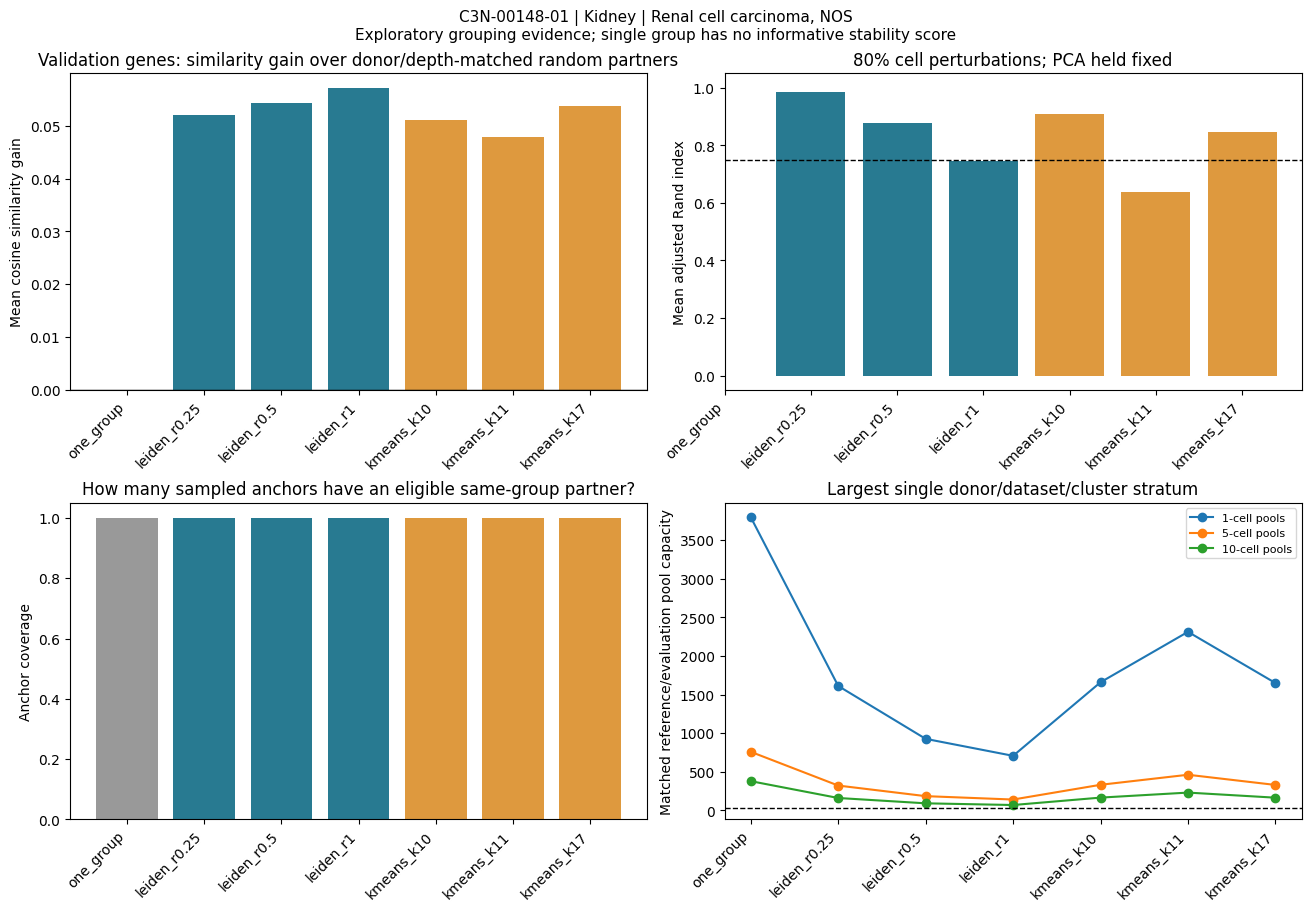

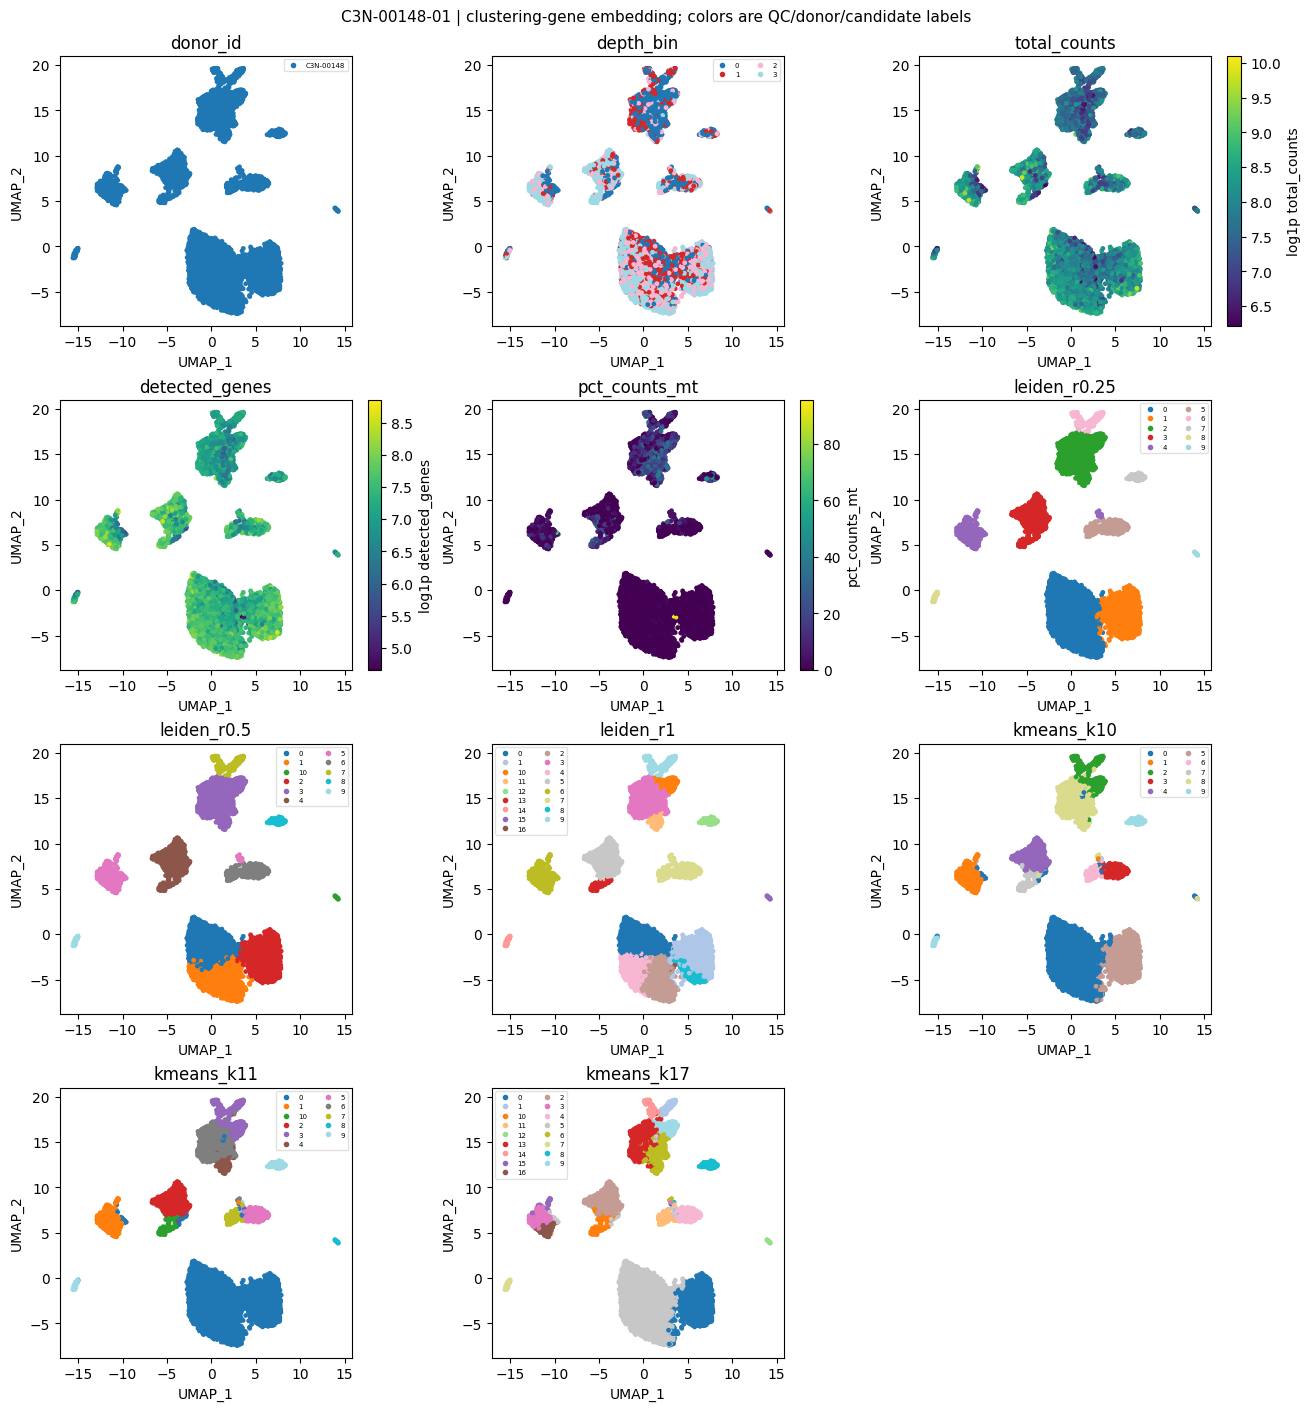

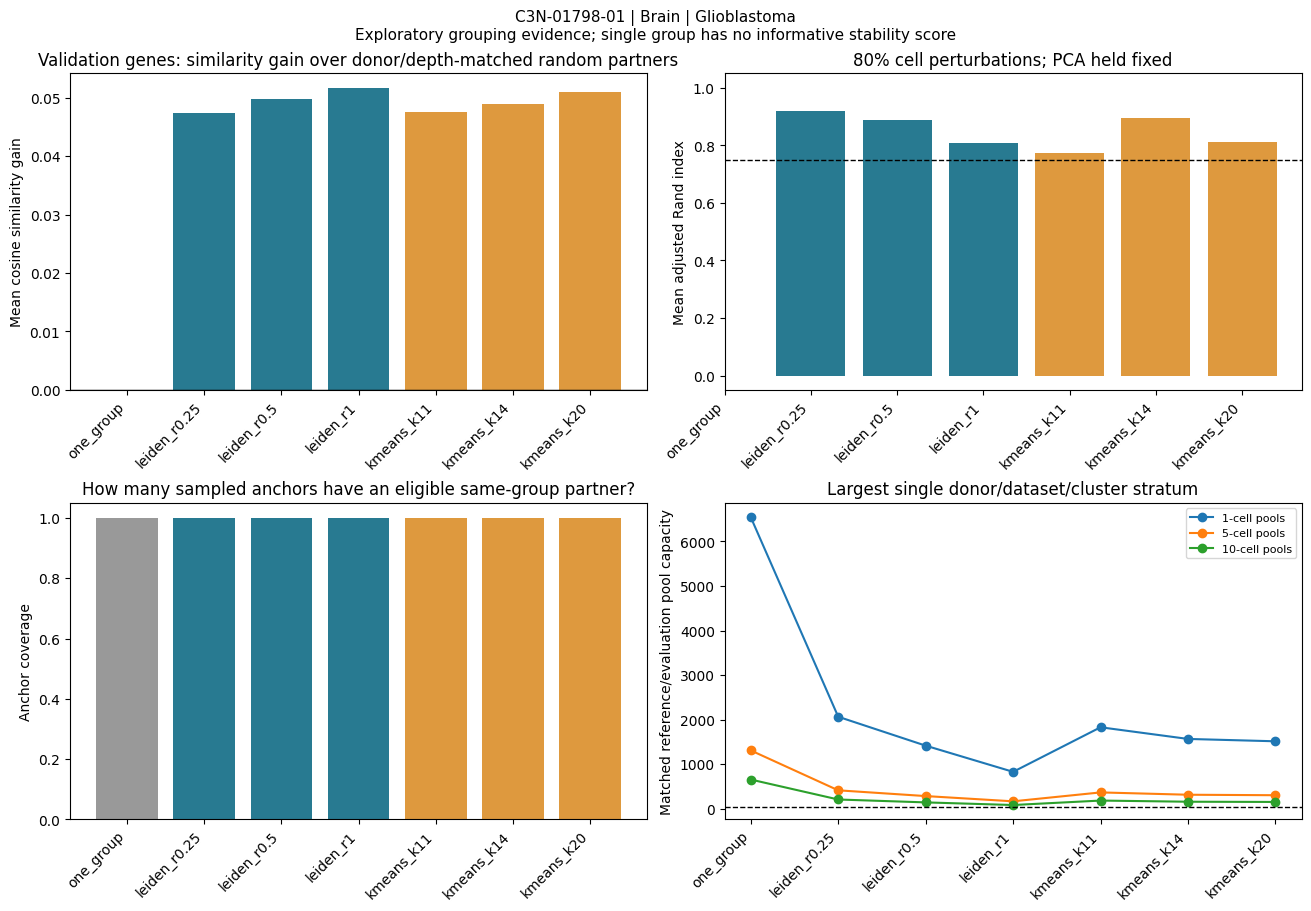

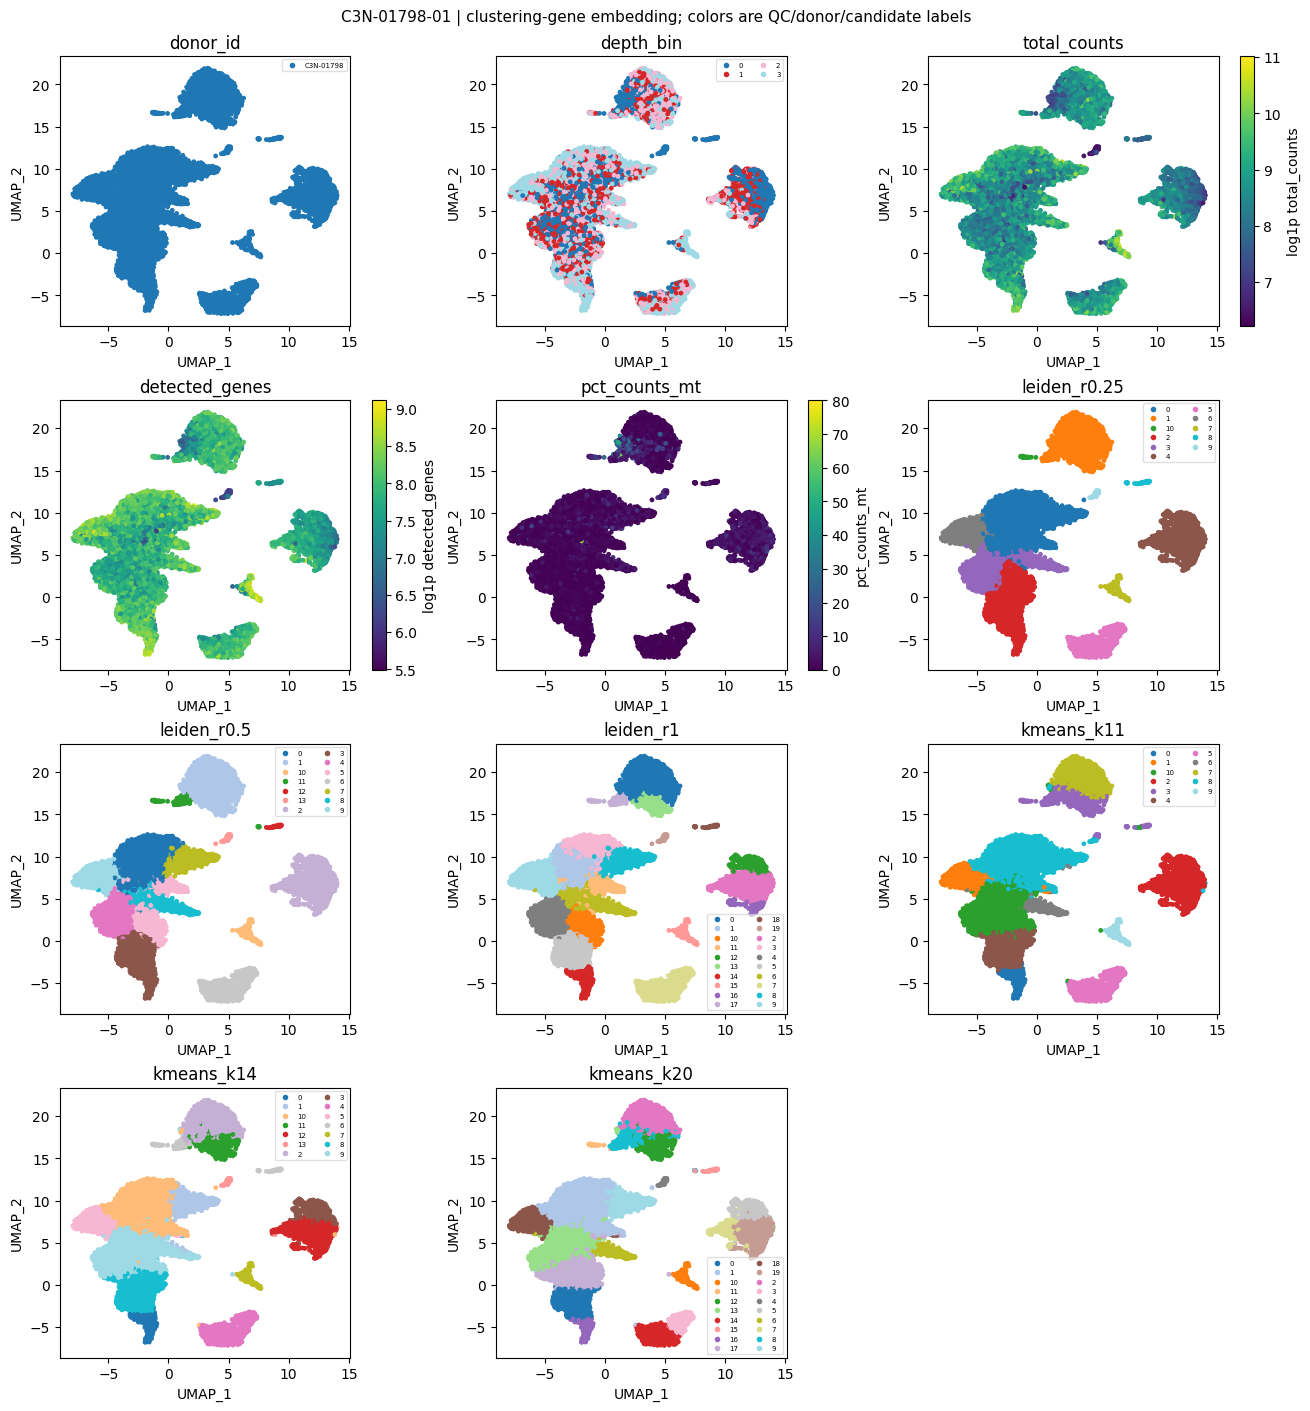

PNG/PDF figures: /home/akash1/scgpt-cna/clustering_analysis/results/20261123T203510387036Z_lab/figures


In [ ]:
# 6 — Report figures. These cells only use saved tables and embeddings.
metrics=pd.read_csv(RUN_DIR/'candidate_metrics.csv')
capacity=pd.read_csv(RUN_DIR/'pool_capacities.csv')
FIG=RUN_DIR/'figures';FIG.mkdir(exist_ok=True)

def save_plot(fig,name):
    fig.savefig(FIG/f'{name}.png',dpi=220,bbox_inches='tight');fig.savefig(FIG/f'{name}.pdf',bbox_inches='tight')
    plt.show();plt.close(fig)

for record in inventory.to_dict('records'):
    sid=record['sample_id'];m=metrics.loc[metrics.sample_id.eq(sid)].reset_index(drop=True)
    names=m.candidate.tolist();x=np.arange(len(m))
    fig,axes=plt.subplots(2,2,figsize=(13,9),constrained_layout=True)
    colors=['#999999' if a=='one_group' else ('#287A91' if a.startswith('leiden') else '#DE993E') for a in names]
    axes[0,0].bar(x,m.mean_validation_cosine_gain,color=colors);axes[0,0].axhline(0,color='black',lw=1)
    axes[0,0].set(title='Validation genes: similarity gain over donor/depth-matched random partners',ylabel='Mean cosine similarity gain')
    axes[0,1].bar(x,m.mean_stability_ARI,color=colors);axes[0,1].axhline(.75,color='black',ls='--',lw=1)
    axes[0,1].set(title='80% cell perturbations; PCA held fixed',ylabel='Mean adjusted Rand index',ylim=(-.05,1.05))
    axes[1,0].bar(x,m.coherence_anchor_coverage,color=colors)
    axes[1,0].set(title='How many sampled anchors have an eligible same-group partner?',ylabel='Anchor coverage',ylim=(0,1.05))
    for k in POOL_SIZES:
        part=capacity.loc[capacity.sample_id.eq(sid)&capacity.pool_size.eq(k)].groupby('candidate').matched_pool_capacity.max().reindex(names)
        axes[1,1].plot(x,part,'o-',label=f'{k}-cell pools')
    axes[1,1].axhline(TARGET_POOLS_PER_PARTITION,color='black',ls='--',lw=1)
    axes[1,1].set(title='Largest single donor/dataset/cluster stratum',ylabel='Matched reference/evaluation pool capacity')
    axes[1,1].legend(fontsize=8)
    for ax in axes.flat:ax.set_xticks(x,names,rotation=45,ha='right')
    fig.suptitle(f"{sid} | {record['primary_site']} | {record['diagnosis']}\nExploratory grouping evidence; single group has no informative stability score",fontsize=11)
    save_plot(fig,f'clustering_evidence_{sid}')
    obs=pd.read_csv(RUN_DIR/sid/'cell_metadata_and_candidate_labels.tsv',sep='\t')
    use_umap=obs.UMAP_1.notna().any();xx,yy=('UMAP_1','UMAP_2') if use_umap else ('PC1','PC2')
    fields=['donor_id','depth_bin','total_counts','detected_genes','pct_counts_mt']+[n for n in names if n!='one_group']
    ncol=3;nrow=int(np.ceil(len(fields)/ncol));fig,axes=plt.subplots(nrow,ncol,figsize=(13,3.5*nrow),constrained_layout=True)
    for ax,field in zip(axes.flat,fields):
        if field in ['total_counts','detected_genes','pct_counts_mt']:
            values=np.log1p(obs[field]) if field!='pct_counts_mt' else obs[field]
            im=ax.scatter(obs[xx],obs[yy],c=values,s=6,cmap='viridis',rasterized=True)
            fig.colorbar(im,ax=ax,label=('log1p '+field) if field!='pct_counts_mt' else field)
        else:
            cat=pd.Categorical(obs[field].astype(str));ax.scatter(obs[xx],obs[yy],c=cat.codes,s=6,cmap='tab20',rasterized=True)
            # Match legend colors to the categorical color scale used by scatter.
            if len(cat.categories)<=20:
                from matplotlib.lines import Line2D
                cmap=plt.get_cmap('tab20')
                handles=[Line2D([0],[0],marker='o',ls='',markersize=3,color=cmap(i/max(len(cat.categories)-1,1)),label=str(v)) for i,v in enumerate(cat.categories)]
                ax.legend(handles=handles,fontsize=5,ncol=2,loc='best',framealpha=.6)
        ax.set(title=field,xlabel=xx,ylabel=yy)
    for ax in list(axes.flat)[len(fields):]:ax.set_visible(False)
    fig.suptitle(f'{sid} | clustering-gene embedding; colors are QC/donor/candidate labels',fontsize=11)
    save_plot(fig,f'embedding_diagnostics_{sid}')
print('PNG/PDF figures:',FIG)

In [ ]:
# 7 — Reopen saved results, then run cell 6. No clustering or source reload required.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RUN_DIR=Path('PASTE_PRINTED_CLUSTERING_RUN_DIR_HERE')
assert (RUN_DIR/'completed.json').is_file()
settings=json.loads((RUN_DIR/'configuration.json').read_text())
POOL_SIZES=settings['POOL_SIZES'];TARGET_POOLS_PER_PARTITION=settings['TARGET_POOLS_PER_PARTITION']
inventory=pd.read_csv(RUN_DIR/'input_inventory.tsv',sep='\t')
print('Ready to plot saved grouping evidence:',RUN_DIR)

AssertionError: 

### 2. Cluster + Aggregation Experiment

In [ ]:
# 1 — Configuration. Use your existing scGPT kernel.
from pathlib import Path
from datetime import datetime,timezone
import gc,gzip,hashlib,importlib.util,importlib.metadata,json,sys,time
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.io import mmread
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits
import anndata as ad
from IPython.display import display
ROOT=Path.home()/'scgpt-cna'
RESUME_RUN=None  # Path('...existing aggregation run...'); restores saved settings, no new folder.
MODE='full'  # After a successful pilot, change to 'full' and rerun from here.
DEVICE='cpu'  # 'cuda' for an NVIDIA GPU with a CUDA-enabled PyTorch environment.
LAB_IDS=['C3N-00148-01','C3N-01798-01']
INCLUDE_CENSUS=True
CENSUS_ID='CENSUS_PROXIMAL_TUBULE_256'
# Explicit paths are preferable. None selects the newest completed matching clustering run for each sample.
CLUSTER_RUN_OVERRIDES={}  # e.g. {'C3N-00148-01': Path('..._lab'), CENSUS_ID:Path('..._census')}
LAB_LABEL='leiden_r0.25'  # Later 'leiden_r0.5' creates a separate sensitivity run.
POOL_SIZES=[1,5,10,15]
POOL_SEEDS=[42]  # Add 43 only for a subsequent construction-sensitivity analysis.
MASK_SEEDS=[42] if MODE=='pilot' else [42,43,44,45]
LENGTHS=[1200,2400] if MODE=='pilot' else [1200,2400,4800]
TARGET_REFERENCE=8 if MODE=='pilot' else 32
TARGET_EVALUATION=4 if MODE=='pilot' else 32
MIN_LAB_FAMILIES=4 if MODE=='pilot' else 16
N_CLUSTERS_PER_LAB=1 if MODE=='pilot' else 2
N_CENSUS_BLOCKS=1 if MODE=='pilot' else 3
MIN_CENSUS_FAMILIES=2
MIN_ANCHOR_QUERY_GENES=10
MAX_QUERIES=299
QUERY_FRACTION=.25  # Of detected reserved-panel genes at size 1; frozen thereafter.
N_THREADS=4
BOOTSTRAPS=1000
MODEL=ROOT/'models/whole-human'
HELPER=ROOT/'notebooks/scgpt_session/scgpt_session.py'
PREPROCESS=ROOT/'sanity_check/reference_4068d67/scgpt/preprocess.py'
CENSUS_ANNOTATION=ROOT/'sanity_check/data/census_proximal_tubule_256/reference_raw.h5ad'
assert MODE in {'pilot','full'} and DEVICE in {'cpu','cuda'}
assert POOL_SIZES==sorted(set(POOL_SIZES)) and POOL_SIZES[0]==1
assert LENGTHS==sorted(set(LENGTHS)) and min(LENGTHS)>=1200
assert MAX_QUERIES<min(LENGTHS)-1
if RESUME_RUN is not None:
    RUN_DIR=Path(RESUME_RUN)
    saved_settings=json.loads((RUN_DIR/'run_manifest.json').read_text())
    for key in ['MODE','DEVICE','LAB_IDS','INCLUDE_CENSUS','CENSUS_ID','LAB_LABEL','POOL_SIZES','POOL_SEEDS','MASK_SEEDS','LENGTHS',
        'TARGET_REFERENCE','TARGET_EVALUATION','MIN_LAB_FAMILIES','N_CLUSTERS_PER_LAB','N_CENSUS_BLOCKS',
        'MIN_CENSUS_FAMILIES','MIN_ANCHOR_QUERY_GENES','MAX_QUERIES','QUERY_FRACTION','BOOTSTRAPS']:
        globals()[key]=saved_settings[key]
    if (RUN_DIR/'evaluation_units.csv').is_file():units=pd.read_csv(RUN_DIR/'evaluation_units.csv',dtype={'cluster':str})
else:
    RUN_DIR=ROOT/'aggregation_context/results'/(datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')+'_'+MODE)
    RUN_DIR.mkdir(parents=True,exist_ok=False)

def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024**2),b''):h.update(block)
    return h.hexdigest()
def rng_seed(*parts):return int(hashlib.sha256('|'.join(map(str,parts)).encode()).hexdigest()[:16],16)
def import_exact(name,path):
    spec=importlib.util.spec_from_file_location(name,path);m=importlib.util.module_from_spec(spec)
    sys.modules[name]=m;spec.loader.exec_module(m);return m

def base_id(x):
    import re
    return re.sub(r'\.\d+$','',str(x))

for p in [MODEL/'args.json',MODEL/'vocab.json',MODEL/'best_model.pt',HELPER,PREPROCESS,CENSUS_ANNOTATION]:assert p.is_file(),p
config=json.loads((MODEL/'args.json').read_text());vocab=json.loads((MODEL/'vocab.json').read_text())
assert config['n_bins']==51 and config['max_seq_len']==1200
assert config['USE_GENERATIVE_TRAINING'] and config['MVC'] and config['input_style']=='binned'
# Import pinned preprocessing only; weights load at first model call.
historical=import_exact('aggregate_pinned_preprocess',PREPROCESS)
assert historical._digitize.__defaults__==('one',)
run_settings={k:globals()[k] for k in ['MODE','DEVICE','LAB_IDS','INCLUDE_CENSUS','CENSUS_ID','LAB_LABEL','POOL_SIZES','POOL_SEEDS',
    'MASK_SEEDS','LENGTHS','TARGET_REFERENCE','TARGET_EVALUATION','MIN_LAB_FAMILIES','N_CLUSTERS_PER_LAB','N_CENSUS_BLOCKS',
    'MIN_CENSUS_FAMILIES','MIN_ANCHOR_QUERY_GENES','MAX_QUERIES','QUERY_FRACTION','BOOTSTRAPS']}
run_settings.update(config=config,checkpoint_sha256=sha(MODEL/'best_model.pt'),vocab_sha256=sha(MODEL/'vocab.json'),
    helper_sha256=sha(HELPER),preprocess_sha256=sha(PREPROCESS),census_annotation_sha256=sha(CENSUS_ANNOTATION),
    python=sys.version,versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','anndata','torch','scgpt']},
    limitations=['Aggregate positive-bin reconstruction, not latent individual-cell expression',
      'Original full positive profile defines bins, including hidden query measurements',
      'Only anchor-detected reserved-panel genes are queried; newly detected genes are not the primary target set',
      'Reference-source cell numbers increase with pool size; baseline is matched to pool size',
      'Fixed queries with increasing visible context also lower the hidden-gene fraction',
      'Census donor health/training overlap unconfirmed; small donor blocks remain pilot evidence',
      'Within-unit family bootstrap does not quantify patient-population uncertainty'])
if RESUME_RUN is None:(RUN_DIR/'run_manifest.json').write_text(json.dumps(run_settings,indent=2))
else:
    for key in ['checkpoint_sha256','vocab_sha256','helper_sha256','preprocess_sha256','census_annotation_sha256','config']:
        assert run_settings[key]==saved_settings[key],f'Changed {key}; resume requires exact sources/software.'
print('Output:',RUN_DIR,'| mode:',MODE,'| device:',DEVICE)

Output: /home/akash1/scgpt-cna/aggregation_context/results/20261123T213545773600Z_full | mode: full | device: cpu


In [ ]:
# 2 — Find completed clustering outputs and verify original data provenance.
sample_ids=LAB_IDS+([CENSUS_ID] if INCLUDE_CENSUS else [])
records=[]
for sid in sample_ids:
    if sid in CLUSTER_RUN_OVERRIDES:
        paths=[Path(CLUSTER_RUN_OVERRIDES[sid])]
    else:
        paths=sorted((ROOT/'clustering_analysis/results').glob('*'),reverse=True)
    found=[]
    for path in paths:
        if not (path/'completed.json').is_file() or not (path/'input_inventory.tsv').is_file():continue
        inv=pd.read_csv(path/'input_inventory.tsv',sep='\t',keep_default_na=False)
        if sid not in set(inv.sample_id):continue
        assert inv.sample_id.is_unique
        record=inv.set_index('sample_id').loc[sid].to_dict();record['sample_id']=sid
        record['cluster_run']=str(path);found.append(record);break
    assert found,f'No completed clustering run for {sid}. Set CLUSTER_RUN_OVERRIDES.'
    record=found[0];d=Path(record['cluster_run'])/sid
    audit=json.loads((d/'source_and_preprocessing.json').read_text())
    for f in audit['sources']:assert sha(f['path'])==f['sha256'],f"Changed raw data: {f['path']}"
    for name in ['cell_metadata_and_candidate_labels.tsv','gene_panels_and_features.tsv']:
        assert (d/name).is_file()
        record[name+'_sha256']=sha(d/name)
    record['cluster_configuration_sha256']=sha(Path(record['cluster_run'])/'configuration.json')
    records.append(record)
inventory=pd.DataFrame(records);inventory.to_csv(RUN_DIR/'input_inventory.tsv',sep='\t',index=False)
display(inventory[['sample_id','primary_site','diagnosis','cluster_run']])
print('Saved labels/source partitions will be reused; clustering is not refit.')

,sample_id,primary_site,diagnosis,cluster_run
0,C3N-00148-01,Kidney,"Renal cell carcinoma, NOS",/home/akash1/scgpt-cna/clustering_analysis/res...
1,C3N-01798-01,Brain,Glioblastoma,/home/akash1/scgpt-cna/clustering_analysis/res...
2,CENSUS_PROXIMAL_TUBULE_256,Kidney,Census-annotated proximal-tubule cohort,/home/akash1/scgpt-cna/clustering_analysis/res...


Saved labels/source partitions will be reused; clustering is not refit.


In [ ]:
# 3 — Raw loaders, vocabulary harmonization, pooling/baseline helpers.
annotation=ad.read_h5ad(CENSUS_ANNOTATION,backed='r')
av=annotation.var[['feature_id','feature_name']].copy();annotation.file.close()
av['base_id']=av.feature_id.astype(str).map(base_id)
unamb=av.groupby('base_id').feature_name.nunique()
id_map=av.loc[av.base_id.isin(unamb.index[unamb.eq(1)])].drop_duplicates('base_id').set_index('base_id').feature_name

def load_counts(record):
    if record['source']=='Census':
        a=ad.read_h5ad(record['source_h5ad']);assert 'counts' in a.layers
        X=sparse.csr_matrix(a.layers['counts']).copy()
        ids=record['sample_id']+':'+a.obs.soma_joinid.astype(str).reset_index(drop=True)
        var=pd.DataFrame(dict(gene_id=a.var.feature_id.astype(str).to_numpy(),gene_symbol=a.var.feature_name.astype(str).to_numpy()))
    else:
        f=pd.read_csv(record['features_file'],sep='\t',header=None,dtype=str)
        bc=pd.read_csv(record['barcodes_file'],sep='\t',header=None,dtype=str)[0]
        p=Path(record['matrix_file'])
        with threadpool_limits(limits=N_THREADS):
            if p.suffix=='.gz':
                with gzip.open(p,'rb') as stream:X=mmread(stream).T.tocsr()
            else:X=mmread(p).T.tocsr()
        assert X.shape==(len(bc),len(f)) and bc.is_unique
        gex=f[2].eq('Gene Expression').to_numpy();X=X[:,gex].tocsr()
        var=pd.DataFrame(dict(gene_id=f.loc[gex,0].to_numpy(),gene_symbol=f.loc[gex,1].to_numpy()))
        ids=record['sample_id']+':'+bc
    X.sum_duplicates();X.eliminate_zeros();X.sort_indices()
    assert np.isfinite(X.data).all() and (X.data>=0).all() and np.equal(X.data,np.rint(X.data)).all()
    assert len(ids)==X.shape[0] and pd.Series(ids).is_unique and var.gene_id.is_unique
    return X,np.asarray(ids,dtype=str),var

def map_features(X,var,panels):
    np.testing.assert_array_equal(var.gene_id.astype(str),panels.gene_id.astype(str))
    matched=var.gene_id.map(base_id).map(id_map)
    symbols=matched.where(matched.isin(vocab),var.gene_symbol)
    keep=symbols.isin(vocab)&~symbols.duplicated(keep='first')
    columns=np.flatnonzero(keep)
    genes=np.array([vocab[s] for s in symbols.iloc[columns]],dtype=np.int64)
    assert len(set(genes))==len(genes)
    eligible=panels.iloc[columns].panel.eq('prediction_reserved').to_numpy()
    # Exclude symbols whose duplicate features were used for grouping/validation under another ID.
    used_symbols=set(symbols.loc[panels.panel.ne('prediction_reserved')&symbols.isin(vocab)])
    eligible &= ~symbols.iloc[columns].isin(used_symbols).to_numpy()
    mapped=X[:,columns].tocsr().astype(np.int64);mapped.eliminate_zeros();mapped.sort_indices()
    info=var.iloc[columns].reset_index(drop=True).copy();info['model_symbol']=symbols.iloc[columns].to_numpy()
    info['gene_token']=genes;info['query_eligible']=eligible
    return mapped,genes,eligible,info

def bins_of(row):return np.asarray(historical.binning(row.data.copy(),n_bins=51),dtype=float)
def fit_reference(pool_matrix,reference_rows):
    sums=np.zeros(pool_matrix.shape[1]);support=np.zeros(pool_matrix.shape[1],dtype=np.int64)
    for i in reference_rows:
        r=pool_matrix.getrow(int(i));assert r.nnz
        sums[r.indices]+=bins_of(r);support[r.indices]+=1
    assert support.sum()>0
    constant=float(sums.sum()/support.sum());means=np.full(pool_matrix.shape[1],constant)
    np.divide(sums,support,out=means,where=support>0)
    return means,support,constant

def group_umi(x):return np.select([x==1,x<=4],['1 UMI','2–4 UMIs'],default='5+ UMIs')

def pool_families(matrix,source_rows,partitions,unit_id,construction,nref,neval,query_eligible):
    # source_rows indexes the selected unit's source-cell metadata / count matrix.
    # Only anchors need sufficient reserved-panel expression; other members need not meet that criterion.
    rng=np.random.default_rng(rng_seed('families',unit_id,construction))
    eligible_anchors=np.asarray(matrix[:,query_eligible].getnnz(axis=1)).ravel()>=MIN_ANCHOR_QUERY_GENES
    family=[]
    for partition,nfamilies in [('reference',nref),('evaluation',neval)]:
        candidates=np.asarray(source_rows)[np.asarray(partitions)==partition]
        assert len(candidates)>=nfamilies*max(POOL_SIZES)
        if partition=='evaluation':
            valid=candidates[eligible_anchors[candidates]]
            assert len(valid)>=nfamilies,'Not enough evaluation anchors with reserved-panel expression.'
            anchors=rng.permutation(valid)[:nfamilies]
            remaining=rng.permutation(np.setdiff1d(candidates,anchors))[:nfamilies*(max(POOL_SIZES)-1)]
            members=np.column_stack([anchors,remaining.reshape(nfamilies,max(POOL_SIZES)-1)])
        else:members=rng.permutation(candidates)[:nfamilies*max(POOL_SIZES)].reshape(nfamilies,max(POOL_SIZES))
        for j,m in enumerate(members):family.append((partition,f'{partition}_{j:03d}',m))
    used=np.concatenate([f[2] for f in family]);assert len(used)==len(set(used))
    return family

In [ ]:
# 4 — Select strata by capacity ONLY, then make/save nested pool families.
# No prediction scores, validation gains or target errors are used to choose clusters.
selection=[];candidate_audits=[];unit_records=[]
for record in inventory.to_dict('records'):
    sid=record['sample_id'];cluster_dir=Path(record['cluster_run'])/sid
    obs=pd.read_csv(cluster_dir/'cell_metadata_and_candidate_labels.tsv',sep='\t',dtype={'cell_id':str,'pooling_block':str})
    panels=pd.read_csv(cluster_dir/'gene_panels_and_features.tsv',sep='\t',dtype={'gene_id':str})
    assert obs.cell_id.is_unique and {'reference','evaluation'}.issubset(set(obs.partition))
    X,source_ids,var=load_counts(record)
    np.testing.assert_array_equal(source_ids[obs.source_row.to_numpy(int)],obs.cell_id)
    X=X[obs.source_row.to_numpy(int)].tocsr()
    model_counts,genes,query_eligible,gene_info=map_features(X,var,panels)
    mapping_audit=dict(n_raw_features=X.shape[1],n_model_features=model_counts.shape[1],
        fraction_raw_counts_retained=float(model_counts.sum()/X.sum()),n_query_eligible_features=int(query_eligible.sum()))
    obs['local_row']=np.arange(len(obs))
    is_census=record['source']=='Census'
    label='one_group' if is_census else LAB_LABEL
    assert label in obs
    obs['selected_label']=obs[label].astype(str)
    counts=obs.groupby(['pooling_block','selected_label','partition'],observed=True).size().unstack('partition',fill_value=0)
    for c in ['reference','evaluation']:
        if c not in counts:counts[c]=0
    counts=counts.reset_index();counts['total_cells']=counts.reference+counts.evaluation
    counts['capacity']=np.minimum(counts.reference//max(POOL_SIZES),counts.evaluation//max(POOL_SIZES))
    anchor_ok=np.asarray(model_counts[:,query_eligible].getnnz(axis=1)).ravel()>=MIN_ANCHOR_QUERY_GENES
    for ix,r in counts.iterrows():
        match=obs.pooling_block.eq(r.pooling_block)&obs.selected_label.eq(r.selected_label)&obs.partition.eq('evaluation')
        counts.loc[ix,'eligible_evaluation_anchors']=int(anchor_ok[match].sum())
    counts['capacity']=np.minimum(counts.capacity,counts.eligible_evaluation_anchors).astype(int)
    minimum=MIN_CENSUS_FAMILIES if is_census else MIN_LAB_FAMILIES
    limit=N_CENSUS_BLOCKS if is_census else N_CLUSTERS_PER_LAB
    candidates=counts.loc[counts.capacity.ge(minimum)].sort_values(['total_cells','pooling_block','selected_label'],ascending=[False,True,True]).head(limit)
    counts['selected']=False
    counts.loc[candidates.index,'selected']=True
    counts['sample_id']=sid;counts['label_column']=label;candidate_audits.append(counts)
    assert len(candidates)>0,f'{sid}: no eligible strata for max pool size {max(POOL_SIZES)}. Inspect capacity; explicitly revise the design rather than mixing sources.'
    for number,r in enumerate(candidates.itertuples(index=False)):
        unit_id=f'{sid}__{label}__stratum{number:02d}'
        out=RUN_DIR/unit_id;out.mkdir()
        (out/'feature_mapping_audit.json').write_text(json.dumps(mapping_audit,indent=2))
        subset=obs.loc[obs.pooling_block.eq(r.pooling_block)&obs.selected_label.eq(r.selected_label)].copy()
        nref=min(TARGET_REFERENCE,int(r.capacity));neval=min(TARGET_EVALUATION,int(r.capacity))
        evidence='small-cohort pilot' if is_census and min(nref,neval)<16 else MODE
        unit=dict(unit_id=unit_id,sample_id=sid,tissue=record['primary_site'],diagnosis=record['diagnosis'],
            label_column=label,cluster=str(r.selected_label),pooling_block=str(r.pooling_block),
            n_source_cells=len(subset),n_reference_families=nref,n_evaluation_families=neval,evidence_status=evidence)
        selection.append(unit);unit_records.append(unit)
        subset.to_csv(out/'source_cells.tsv',sep='\t',index=False)
        gene_info.to_csv(out/'model_genes.tsv',sep='\t',index=False);np.save(out/'gene_tokens.npy',genes)
        np.save(out/'query_eligible.npy',query_eligible)
        valcols=np.flatnonzero(panels.used_for_validation.astype(str).str.lower().eq('true'))
        assert len(valcols)>0 and panels.iloc[valcols].panel.eq('validation').all()
        V=X[:,valcols].tocsr().astype(float)
        Vsingle=V.copy();den=np.asarray(Vsingle.sum(axis=1)).ravel();Vsingle=sparse.diags(1e4/np.maximum(den,1)).dot(Vsingle).tocsr()
        Vsingle.data=np.log1p(Vsingle.data);Vsingle=normalize(Vsingle).tocsr()
        for construction in POOL_SEEDS:
            fam=pool_families(model_counts,subset.local_row.to_numpy(int),subset.partition.to_numpy(),unit_id,construction,nref,neval,query_eligible)
            matrices=[];validation=[];metadata=[];memberships=[];queries=[]
            for partition,family_id,members in fam:
                anchor=model_counts.getrow(int(members[0]))
                qcols=anchor.indices[query_eligible[anchor.indices]]
                for mask in MASK_SEEDS:
                    if partition=='evaluation':
                        nq=min(MAX_QUERIES,max(1,int(np.floor(QUERY_FRACTION*len(qcols)))))
                        chosen=np.random.default_rng(rng_seed('queries',unit_id,construction,family_id,mask)).choice(qcols,nq,replace=False)
                        pos=np.searchsorted(anchor.indices,chosen)
                        queries.append(pd.DataFrame(dict(family_id=family_id,mask_seed=mask,gene_token=genes[chosen],anchor_umi=anchor.data[pos])))
                for size in POOL_SIZES:
                    used=members[:size]
                    row=sparse.csr_matrix(model_counts[used].sum(axis=0));row.eliminate_zeros();row.sort_indices()
                    np.testing.assert_array_equal(row.toarray(),model_counts[used].sum(axis=0))
                    assert row.nnz and np.equal(row.data,np.rint(row.data)).all()
                    vrow=sparse.csr_matrix(V[used].sum(axis=0));vrow.eliminate_zeros()
                    j=len(matrices);matrices.append(row);validation.append(vrow)
                    source_totals=np.asarray(model_counts[used].sum(axis=1)).ravel()
                    s=Vsingle[used];valid=np.flatnonzero(np.asarray(s.getnnz(axis=1))>0)
                    homogeneity=np.nan
                    if len(valid)>1:
                        vv=s[valid];summed=sparse.csr_matrix(vv.sum(axis=0))
                        homogeneity=float((summed.multiply(summed).sum()-vv.multiply(vv).sum())/(len(valid)*(len(valid)-1)))
                    bb=bins_of(row);_,freq=np.unique(bb,return_counts=True)
                    metadata.append(dict(unit_id=unit_id,construction_seed=construction,pool_row=j,partition=partition,family_id=family_id,
                        pool_size=size,total_counts=float(row.sum()),detected_model_genes=row.nnz,
                        singleton_fraction=float(np.mean(row.data==1)),occupied_bins=len(freq),dominant_bin_fraction=float(freq.max()/row.nnz),
                        largest_source_share=float(source_totals.max()/source_totals.sum()),within_pool_validation_cosine=homogeneity))
                    for rank,source_row in enumerate(used):
                        source=obs.iloc[source_row]
                        memberships.append(dict(unit_id=unit_id,construction_seed=construction,partition=partition,family_id=family_id,
                            pool_size=size,member_rank=rank,cell_id=source.cell_id,source_row=int(source.source_row),pooling_block=source.pooling_block,
                            cluster=str(source.selected_label)))
            pm=sparse.vstack(matrices,format='csr');vm=sparse.vstack(validation,format='csr');meta=pd.DataFrame(metadata)
            membership=pd.DataFrame(memberships)
            # Largest pools are disjoint; smaller pools are exact prefixes, not independent new observations.
            maxmem=membership.loc[membership.pool_size.eq(max(POOL_SIZES))]
            assert not maxmem.cell_id.duplicated().any()
            assert maxmem.pooling_block.nunique()==1 and maxmem.cluster.nunique()==1
            assert set(maxmem.loc[maxmem.partition.eq('reference'),'cell_id']).isdisjoint(maxmem.loc[maxmem.partition.eq('evaluation'),'cell_id'])
            for _,g in membership.groupby(['partition','family_id']):
                previous=set()
                for size in POOL_SIZES:
                    current=set(g.loc[g.pool_size.eq(size),'cell_id']);assert previous.issubset(current) and len(current)==size;previous=current
            sparse.save_npz(out/f'pool_counts_seed{construction}.npz',pm)
            sparse.save_npz(out/f'validation_pool_counts_seed{construction}.npz',vm)
            meta.to_csv(out/f'pool_metadata_seed{construction}.csv',index=False)
            membership.to_csv(out/f'pool_memberships_seed{construction}.csv',index=False)
            pd.concat(queries,ignore_index=True).to_csv(out/f'frozen_queries_seed{construction}.csv',index=False)
        print(unit_id,'reference/evaluation families:',nref,neval,'|',evidence,flush=True)
    del X,model_counts;gc.collect()
units=pd.DataFrame(unit_records);units.to_csv(RUN_DIR/'evaluation_units.csv',index=False)
pd.concat(candidate_audits,ignore_index=True).to_csv(RUN_DIR/'stratum_feasibility.csv',index=False)
(RUN_DIR/'pools_prepared.json').write_text(json.dumps(dict(complete=True),indent=2))
display(units)
print('All raw pool sums, nested memberships, query-panel restrictions and source partitions verified.')

C3N-00148-01__leiden_r0.25__stratum00 reference/evaluation families: 32 32 | full
C3N-00148-01__leiden_r0.25__stratum01 reference/evaluation families: 32 32 | full
C3N-01798-01__leiden_r0.25__stratum00 reference/evaluation families: 32 32 | full
C3N-01798-01__leiden_r0.25__stratum01 reference/evaluation families: 32 32 | full
CENSUS_PROXIMAL_TUBULE_256__one_group__stratum00 reference/evaluation families: 3 3 | small-cohort pilot


,unit_id,sample_id,tissue,diagnosis,label_column,cluster,pooling_block,n_source_cells,n_reference_families,n_evaluation_families,evidence_status
0,C3N-00148-01__leiden_r0.25__stratum00,C3N-00148-01,Kidney,"Renal cell carcinoma, NOS",leiden_r0.25,0,C3N-00148|C3N-00148-01,3297,32,32,full
1,C3N-00148-01__leiden_r0.25__stratum01,C3N-00148-01,Kidney,"Renal cell carcinoma, NOS",leiden_r0.25,1,C3N-00148|C3N-00148-01,1323,32,32,full
2,C3N-01798-01__leiden_r0.25__stratum00,C3N-01798-01,Brain,Glioblastoma,leiden_r0.25,0,C3N-01798|C3N-01798-01,4222,32,32,full
3,C3N-01798-01__leiden_r0.25__stratum01,C3N-01798-01,Brain,Glioblastoma,leiden_r0.25,1,C3N-01798|C3N-01798-01,2106,32,32,full
4,CENSUS_PROXIMAL_TUBULE_256__one_group__stratum00,CENSUS_PROXIMAL_TUBULE_256,Kidney,Census-annotated proximal-tubule cohort,one_group,0,TTx|9ea768a2-87ab-46b6-a73d-c4e915f25af3,118,3,3,small-cohort pilot


All raw pool sums, nested memberships, query-panel restrictions and source partitions verified.


,unit_id,pool_size,partition,n_pools,median_total_counts,median_detected_genes,median_singleton_fraction,median_occupied_bins,median_largest_source_share,mean_within_pool_validation_cosine
0,C3N-00148-01__leiden_r0.25__stratum00,1,evaluation,32,2829.5,1532.5,0.748,6.0,1.000,NaN
1,C3N-00148-01__leiden_r0.25__stratum00,1,reference,32,3287.0,1857.0,0.738,6.0,1.000,NaN
2,C3N-00148-01__leiden_r0.25__stratum00,5,evaluation,32,16400.0,5617.5,0.548,9.0,0.284,0.318
3,C3N-00148-01__leiden_r0.25__stratum00,5,reference,32,16743.0,5603.0,0.553,9.0,0.288,0.321
4,C3N-00148-01__leiden_r0.25__stratum00,10,evaluation,32,32793.5,8165.5,0.445,11.5,0.164,0.318
5,C3N-00148-01__leiden_r0.25__stratum00,10,reference,32,33773.5,8170.0,0.447,12.0,0.174,0.319
6,C3N-00148-01__leiden_r0.25__stratum00,15,evaluation,32,48807.0,9763.5,0.393,13.0,0.117,0.315
7,C3N-00148-01__leiden_r0.25__stratum00,15,reference,32,51895.5,9955.5,0.389,14.0,0.126,0.319
8,C3N-00148-01__leiden_r0.25__stratum01,1,evaluation,32,3059.0,1629.5,0.757,6.0,1.000,NaN
9,C3N-00148-01__leiden_r0.25__stratum01,1,reference,32,3089.0,1763.0,0.750,5.0,1.000,NaN


,unit_id,construction_seed,pool_size,n_reference,n_evaluation,mean_cross_partition_validation_cosine
0,C3N-00148-01__leiden_r0.25__stratum00,42,1,32,32,0.317
1,C3N-00148-01__leiden_r0.25__stratum00,42,5,32,32,0.648
2,C3N-00148-01__leiden_r0.25__stratum00,42,10,32,32,0.776
3,C3N-00148-01__leiden_r0.25__stratum00,42,15,32,32,0.830
4,C3N-00148-01__leiden_r0.25__stratum01,42,1,32,32,0.318
5,C3N-00148-01__leiden_r0.25__stratum01,42,5,32,32,0.663
6,C3N-00148-01__leiden_r0.25__stratum01,42,10,32,32,0.787
7,C3N-00148-01__leiden_r0.25__stratum01,42,15,32,32,0.842
8,C3N-01798-01__leiden_r0.25__stratum00,42,1,32,32,0.447
9,C3N-01798-01__leiden_r0.25__stratum00,42,5,32,32,0.784


More coverage or cross-pool agreement is descriptive; not proof of latent biological denoising.


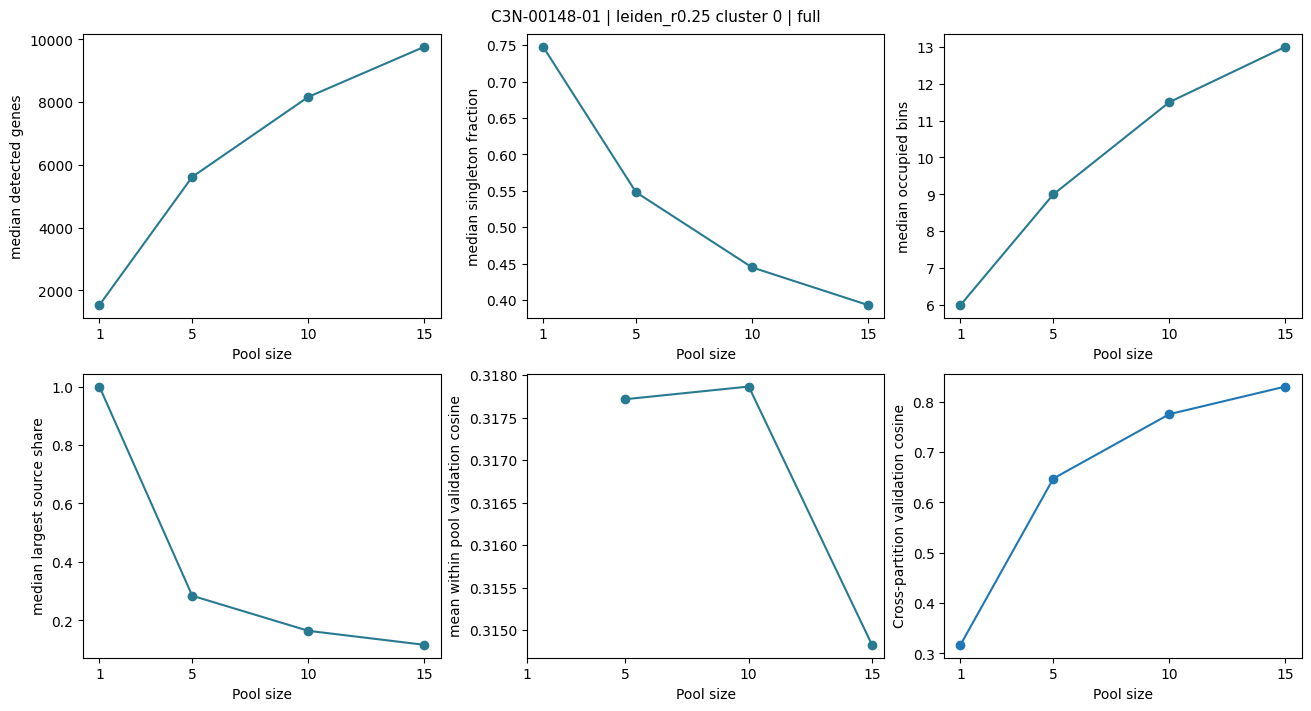

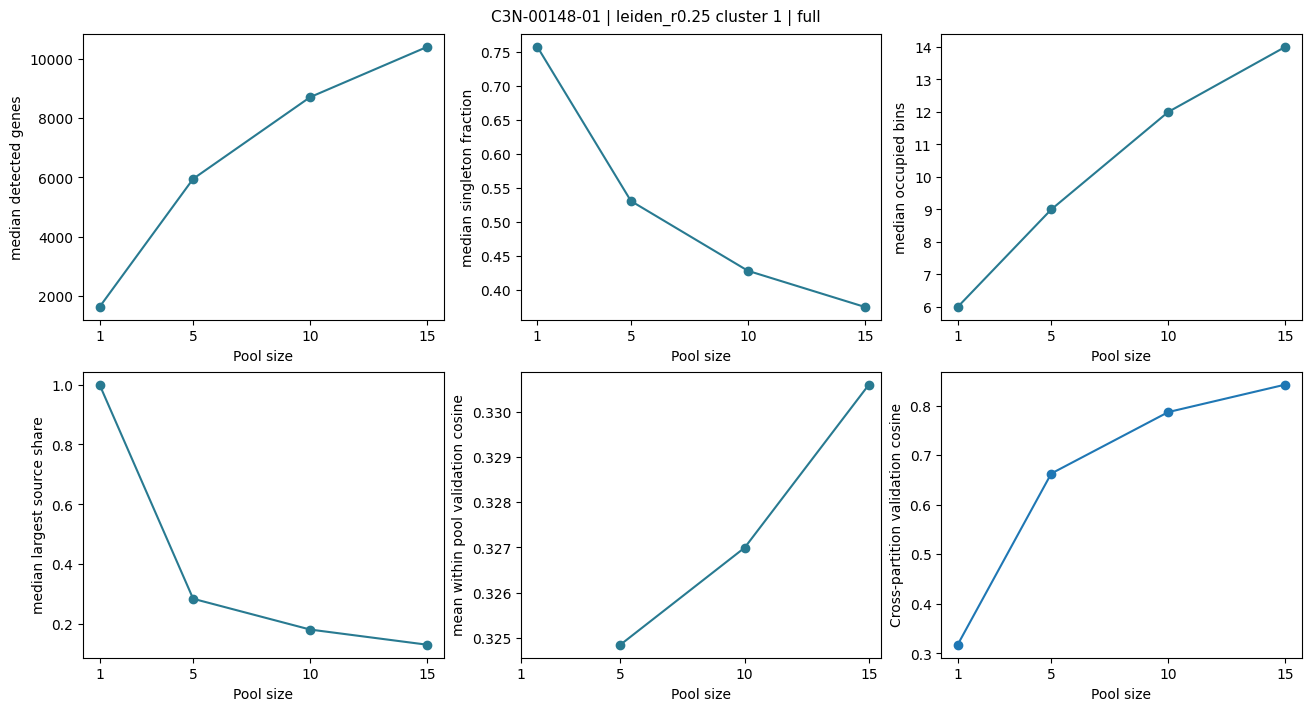

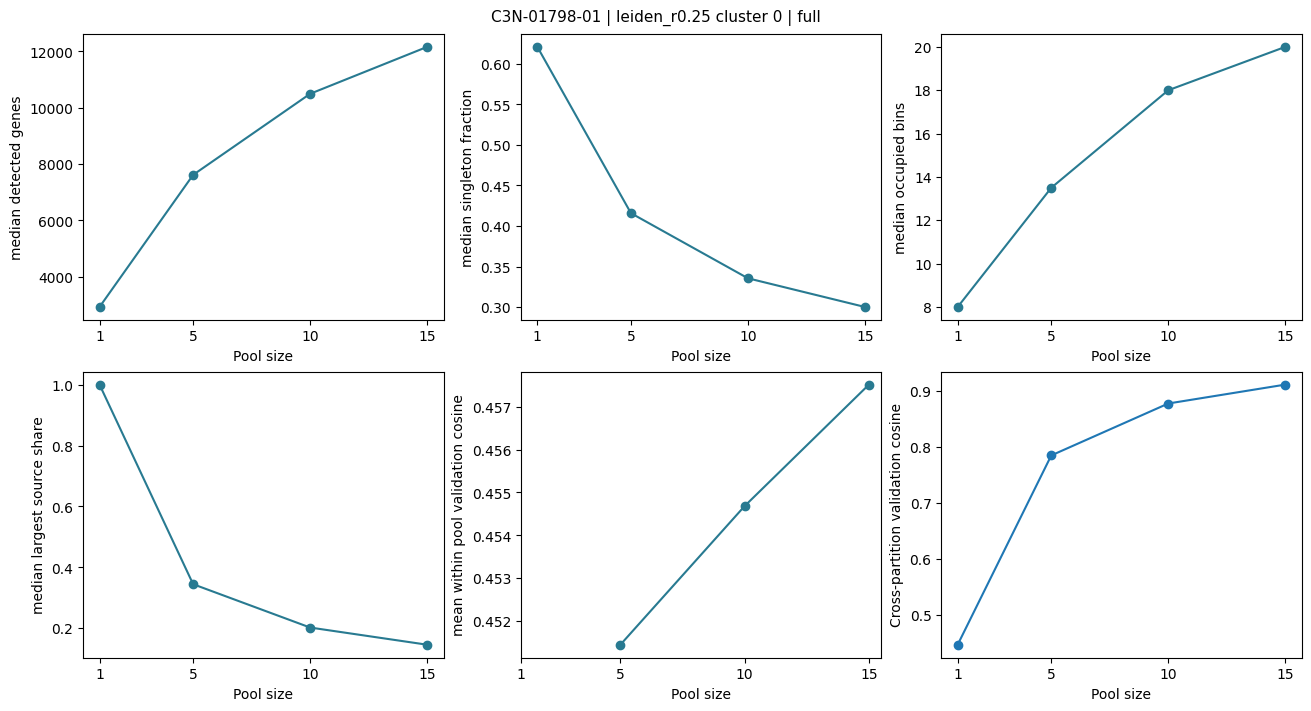

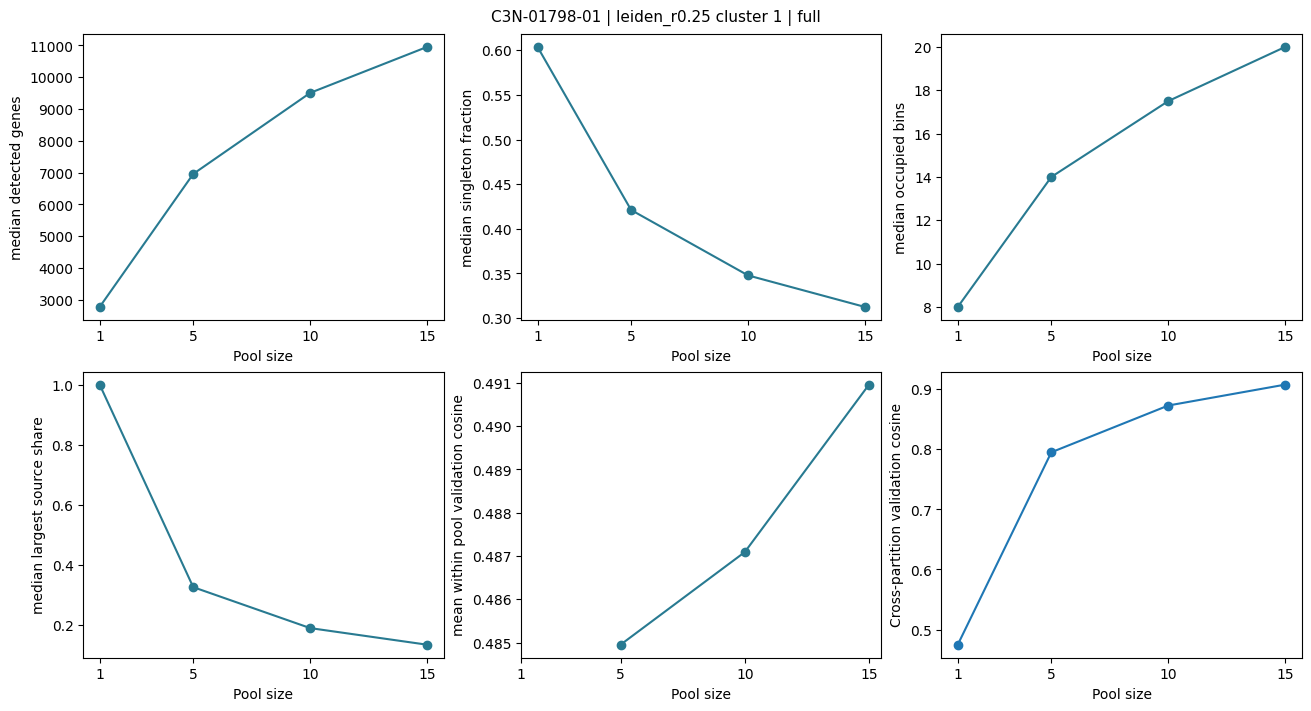

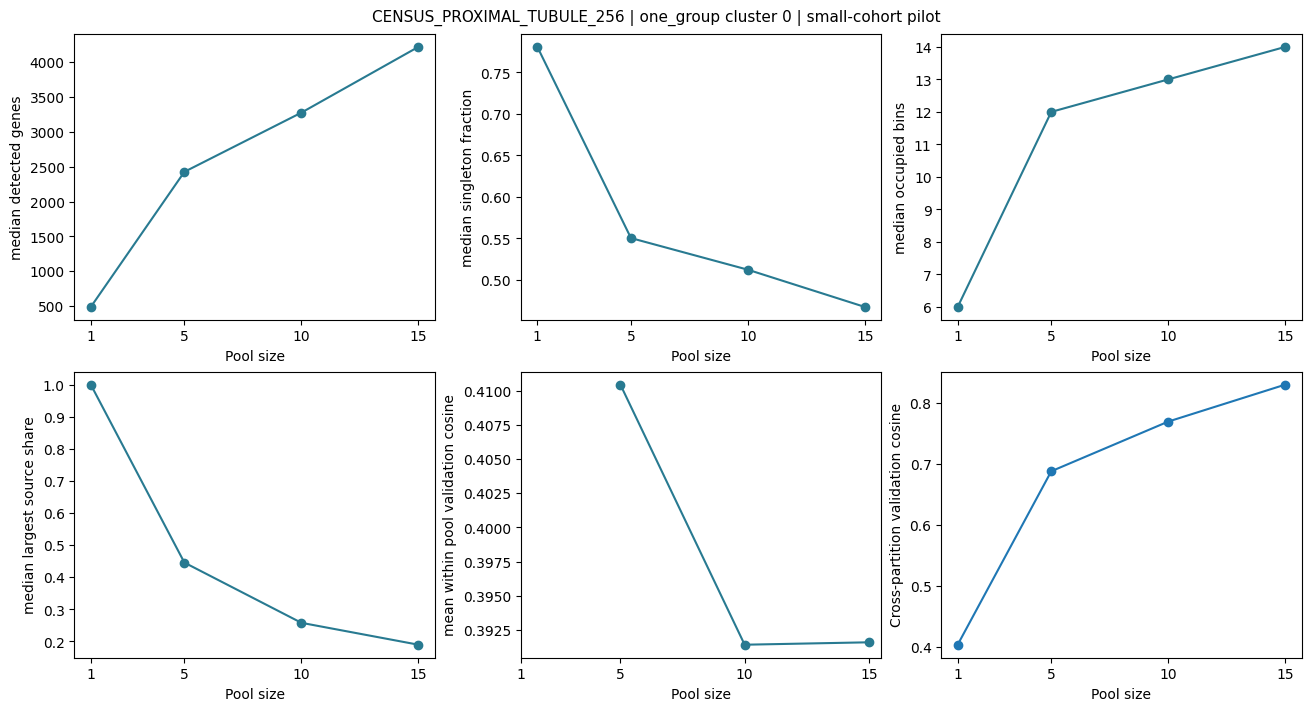

In [ ]:
# 5 — Aggregation-quality diagnostics independent of scGPT inference.
profiles=[];repro=[]
for u in units.to_dict('records'):
    d=RUN_DIR/u['unit_id']
    for construction in POOL_SEEDS:
        m=pd.read_csv(d/f'pool_metadata_seed{construction}.csv');m['sample_id']=u['sample_id'];m['cluster']=u['cluster'];profiles.append(m)
        v=sparse.load_npz(d/f'validation_pool_counts_seed{construction}.npz').astype(float)
        total=np.asarray(v.sum(axis=1)).ravel();v=sparse.diags(1e4/np.maximum(total,1)).dot(v).tocsr();v.data=np.log1p(v.data)
        v=normalize(v).tocsr()
        for size in POOL_SIZES:
            r=m.loc[m.partition.eq('reference')&m.pool_size.eq(size),'pool_row'].to_numpy(int)
            e=m.loc[m.partition.eq('evaluation')&m.pool_size.eq(size),'pool_row'].to_numpy(int)
            # Mean cosine over all disjoint reference/evaluation pool pairs, without treating pairs as independent.
            mr=sparse.csr_matrix(v[r].mean(axis=0));me=sparse.csr_matrix(v[e].mean(axis=0))
            repro.append(dict(unit_id=u['unit_id'],construction_seed=construction,pool_size=size,
                n_reference=len(r),n_evaluation=len(e),mean_cross_partition_validation_cosine=float(mr.multiply(me).sum())))
pool_profiles=pd.concat(profiles,ignore_index=True);pool_profiles.to_csv(RUN_DIR/'pool_profiles.csv',index=False)
reproducibility=pd.DataFrame(repro);reproducibility.to_csv(RUN_DIR/'validation_reproducibility.csv',index=False)
quality=pool_profiles.groupby(['unit_id','pool_size','partition'],as_index=False).agg(
    n_pools=('family_id','size'),median_total_counts=('total_counts','median'),median_detected_genes=('detected_model_genes','median'),
    median_singleton_fraction=('singleton_fraction','median'),median_occupied_bins=('occupied_bins','median'),
    median_largest_source_share=('largest_source_share','median'),mean_within_pool_validation_cosine=('within_pool_validation_cosine','mean'))
quality.to_csv(RUN_DIR/'aggregation_quality_summary.csv',index=False)
display(quality.round(3));display(reproducibility.round(3))
print('More coverage or cross-pool agreement is descriptive; not proof of latent biological denoising.')
import matplotlib.pyplot as plt
quality_figures=RUN_DIR/'figures';quality_figures.mkdir(exist_ok=True)
for u in units.to_dict('records'):
    fig,axes=plt.subplots(2,3,figsize=(13,7),constrained_layout=True)
    p=quality.loc[quality.unit_id.eq(u['unit_id'])&quality.partition.eq('evaluation')].sort_values('pool_size')
    columns=['median_detected_genes','median_singleton_fraction','median_occupied_bins','median_largest_source_share','mean_within_pool_validation_cosine']
    for ax,col in zip(axes.flat,columns):
        ax.plot(p.pool_size,p[col],'o-',color='#287A91');ax.set(xlabel='Pool size',ylabel=col.replace('_',' '),xticks=POOL_SIZES)
    for construction in POOL_SEEDS:
        z=reproducibility.loc[reproducibility.unit_id.eq(u['unit_id'])&reproducibility.construction_seed.eq(construction)].sort_values('pool_size')
        axes[1,2].plot(z.pool_size,z.mean_cross_partition_validation_cosine,'o-',label=f'seed {construction}')
    axes[1,2].set(xlabel='Pool size',ylabel='Cross-partition validation cosine',xticks=POOL_SIZES)
    fig.suptitle(f"{u['sample_id']} | {u['label_column']} cluster {u['cluster']} | {u['evidence_status']}",fontsize=11)
    fig.savefig(quality_figures/f"aggregation_quality_{u['unit_id']}.png",dpi=220,bbox_inches='tight')
    fig.savefig(quality_figures/f"aggregation_quality_{u['unit_id']}.pdf",bbox_inches='tight')
    plt.show();plt.close(fig)

In [ ]:
# 6 — Freeze each condition's targets, nested contexts and matched reference baseline.
# No model inference. Bins are defined once per complete positive pooled profile.
for u in units.to_dict('records'):
    d=RUN_DIR/u['unit_id'];genes=np.load(d/'gene_tokens.npy')
    for construction in POOL_SEEDS:
        pm=sparse.load_npz(d/f'pool_counts_seed{construction}.npz')
        meta=pd.read_csv(d/f'pool_metadata_seed{construction}.csv')
        anchors=pd.read_csv(d/f'frozen_queries_seed{construction}.csv')
        tasks=[];arr={}
        for size in POOL_SIZES:
            refs=meta.loc[meta.partition.eq('reference')&meta.pool_size.eq(size),'pool_row'].to_numpy(int)
            means,support,constant=fit_reference(pm,refs)
            np.savez_compressed(d/f'baseline_seed{construction}_k{size}.npz',means=means,support=support,constant=constant)
            for r in meta.loc[meta.partition.eq('evaluation')&meta.pool_size.eq(size)].itertuples(index=False):
                row=pm.getrow(r.pool_row);bb=bins_of(row);position={int(t):j for j,t in enumerate(genes[row.indices])}
                for mask in MASK_SEEDS:
                    part=anchors.loc[anchors.family_id.eq(r.family_id)&anchors.mask_seed.eq(mask)]
                    assert 0<len(part)<=MAX_QUERIES
                    qi=np.array([position[int(t)] for t in part.gene_token],dtype=int)
                    candidates=np.setdiff1d(np.arange(row.nnz),qi)
                    order=np.random.default_rng(rng_seed('context',u['unit_id'],construction,r.family_id,size,mask)).permutation(candidates)
                    prefix=f'r{r.pool_row}_m{mask}'
                    arr[prefix+'_query_positions']=qi;arr[prefix+'_visible_order']=order
                    target=bb[qi]
                    for j,t in enumerate(part.itertuples(index=False)):
                        tasks.append(dict(unit_id=u['unit_id'],construction_seed=construction,pool_row=int(r.pool_row),family_id=r.family_id,
                            pool_size=size,mask_seed=mask,gene_token=int(t.gene_token),anchor_umi=int(t.anchor_umi),
                            pooled_umi=int(row.data[qi[j]]),target_bin=float(target[j]),reference_support=int(support[row.indices[qi[j]]])))
                    # Uniform count multiplication must not change this profile's historical bins.
                    if mask==MASK_SEEDS[0]:np.testing.assert_array_equal(bb,historical.binning(row.data.copy()*2,n_bins=51))
        q=pd.DataFrame(tasks)
        for _,p in q.groupby(['family_id','mask_seed']):
            reference=None
            for _,s in p.groupby('pool_size'):
                ids=s.gene_token.to_numpy()
                if reference is None:reference=ids
                else:np.testing.assert_array_equal(ids,reference)
        q.to_csv(d/f'frozen_tasks_seed{construction}.csv.gz',index=False)
        np.savez_compressed(d/f'context_orders_seed{construction}.npz',**arr)
(RUN_DIR/'tasks_prepared.json').write_text(json.dumps(dict(complete=True),indent=2))
print('Fixed query identities across pool sizes; fixed pooled targets across lengths. Ready for inference.')

Fixed query identities across pool sizes; fixed pooled targets across lengths. Ready for inference.


In [ ]:
# 7 — Frozen checkpoint inference. Restart-safe: complete unit/construction/mask files are reused.
import torch
assert (RUN_DIR/'tasks_prepared.json').is_file()
torch.set_num_threads(N_THREADS)
assert DEVICE=='cpu' or torch.cuda.is_available(),'CUDA unavailable: keep CPU or use a CUDA-enabled environment/GPU allocation.'
if DEVICE=='cuda':
    torch.backends.cuda.matmul.allow_tf32=False
    torch.backends.cudnn.allow_tf32=False
session=import_exact('aggregate_verified_session',HELPER)
model,loaded_vocab,loaded_config=session.load_model(MODEL)
assert loaded_config==config and loaded_vocab.get_stoi()==vocab
model=model.eval().requires_grad_(False).to(DEVICE)
cls_id=vocab['<cls>'];pad_value=config.get('pad_value',-2)

@torch.inference_mode()
def model_predict(known_genes,known_bins,query_genes):
    ki=torch.tensor(np.r_[cls_id,known_genes],dtype=torch.long,device=DEVICE).unsqueeze(0)
    kv=torch.tensor(np.r_[pad_value,known_bins],dtype=torch.float32,device=DEVICE).unsqueeze(0)
    qi=torch.tensor(query_genes,dtype=torch.long,device=DEVICE).unsqueeze(0)
    o=model(ki,kv,qi)
    return {h:o[h].detach().cpu().numpy().reshape(-1) for h in ['GEP','MVC']}

# Check GPU/CPU equivalence on the same actual prepared input before any CUDA benchmark.
if DEVICE=='cuda':
    u=units.iloc[0];d=RUN_DIR/u.unit_id;c=POOL_SEEDS[0];mask=MASK_SEEDS[0]
    pm=sparse.load_npz(d/f'pool_counts_seed{c}.npz');genes=np.load(d/'gene_tokens.npy')
    tasks=pd.read_csv(d/f'frozen_tasks_seed{c}.csv.gz');p=tasks.loc[tasks.mask_seed.eq(mask)].iloc[0];row=pm.getrow(int(p.pool_row))
    with np.load(d/f'context_orders_seed{c}.npz') as orders:
        qi=orders[f'r{int(p.pool_row)}_m{mask}_query_positions'];vi=orders[f'r{int(p.pool_row)}_m{mask}_visible_order'][:max(0,1200-1-len(qi))]
    bb=bins_of(row);args=(genes[row.indices[vi]],bb[vi],genes[row.indices[qi]])
    gpu=model_predict(*args)
    model=model.cpu();DEVICE='cpu';cpu=model_predict(*args)
    DEVICE='cuda';model=model.to(DEVICE)
    for h in ['GEP','MVC']:np.testing.assert_allclose(gpu[h],cpu[h],atol=2e-3,rtol=2e-4,err_msg='GPU parity failed; investigate before benchmarking.')
    (RUN_DIR/'gpu_parity.json').write_text(json.dumps({h:float(np.max(abs(gpu[h]-cpu[h]))) for h in gpu},indent=2))

for u in units.to_dict('records'):
    d=RUN_DIR/u['unit_id'];genes=np.load(d/'gene_tokens.npy')
    for construction in POOL_SEEDS:
        pm=sparse.load_npz(d/f'pool_counts_seed{construction}.npz')
        tasks=pd.read_csv(d/f'frozen_tasks_seed{construction}.csv.gz')
        with np.load(d/f'context_orders_seed{construction}.npz') as orders:
            for mask in MASK_SEEDS:
                path=d/f'predictions_seed{construction}_mask{mask}.csv.gz'
                done=d/f'predictions_seed{construction}_mask{mask}.complete.json'
                signature_paths=[RUN_DIR/'run_manifest.json',d/'gene_tokens.npy',d/f'pool_counts_seed{construction}.npz',
                    d/f'frozen_tasks_seed{construction}.csv.gz',d/f'context_orders_seed{construction}.npz']
                signature_paths += [d/f'baseline_seed{construction}_k{k}.npz' for k in POOL_SIZES]
                input_signature=hashlib.sha256('|'.join(sha(p) for p in signature_paths).encode()).hexdigest()
                if path.is_file() and done.is_file():
                    stamp=json.loads(done.read_text())
                    assert sha(path)==stamp['sha256'] and input_signature==stamp['input_signature'],'Saved inference inputs changed; start a separate run.'
                    print('Reusing:',path.name,flush=True);continue
                frames=[];inputs=[]
                for (size,pool_row),part in tasks.loc[tasks.mask_seed.eq(mask)].groupby(['pool_size','pool_row'],sort=True):
                    row=pm.getrow(int(pool_row));bb=bins_of(row)
                    qi=orders[f'r{pool_row}_m{mask}_query_positions'];order=orders[f'r{pool_row}_m{mask}_visible_order']
                    np.testing.assert_array_equal(genes[row.indices[qi]],part.gene_token)
                    np.testing.assert_array_equal(bb[qi],part.target_bin)
                    with np.load(d/f'baseline_seed{construction}_k{size}.npz') as b:
                        means=b['means'];constant=float(b['constant'])
                    previous=set()
                    for length in LENGTHS:
                        vi=order[:length-1-len(qi)]
                        assert previous.issubset(set(vi)) and set(vi).isdisjoint(qi);previous=set(vi)
                        assert 1+len(vi)+len(qi)<=length and len(vi)>0
                        pred=model_predict(genes[row.indices[vi]],bb[vi],genes[row.indices[qi]])
                        shuffled=np.random.default_rng(rng_seed('shuffle',u['unit_id'],construction,pool_row,mask,length)).permutation(bb[vi])
                        sh=model_predict(genes[row.indices[vi]],shuffled,genes[row.indices[qi]])
                        offset=float(np.mean(bb[vi]-means[row.indices[vi]]))
                        pred.update(GEP_shuffled=sh['GEP'],MVC_shuffled=sh['MVC'],gene_mean=means[row.indices[qi]],
                            gene_mean_plus_offset=means[row.indices[qi]]+offset,visible_mean=np.full(len(qi),bb[vi].mean()),
                            reference_constant=np.full(len(qi),constant))
                        assert all(np.asarray(v).shape==(len(part),) and np.isfinite(v).all() for v in pred.values())
                        frame=part.copy();frame['context_budget']=length
                        for h,v in pred.items():frame[h]=v
                        frames.append(frame)
                        inputs.append(dict(unit_id=u['unit_id'],construction_seed=construction,pool_row=pool_row,family_id=part.family_id.iloc[0],
                            pool_size=size,mask_seed=mask,context_budget=length,n_visible=len(vi),n_queries=len(qi),n_detected=row.nnz,
                            visible_fraction=len(vi)/row.nnz,query_fraction_genes=len(qi)/(len(vi)+len(qi)),token_budget_gene_fraction=(len(vi)+len(qi))/row.nnz,
                            saturated=len(vi)==len(order),visible_offset=offset))
                    print(u['unit_id'],'seed',construction,'mask',mask,'pool size',size,'row',pool_row,'done',flush=True)
                out=pd.concat(frames,ignore_index=True)
                out.to_csv(path,index=False)
                pd.DataFrame(inputs).to_csv(d/f'inference_inputs_seed{construction}_mask{mask}.csv',index=False)
                done.write_text(json.dumps(dict(sha256=sha(path),input_signature=input_signature),indent=2))
(RUN_DIR/'inference_complete.json').write_text(json.dumps(dict(complete=True),indent=2))
print('Inference saved:',RUN_DIR)

Strict load: 163 checkpoint tensors; no omitted tensors.
C3N-00148-01__leiden_r0.25__stratum00 seed 42 mask 42 pool size 1 row 128 done
C3N-00148-01__leiden_r0.25__stratum00 seed 42 mask 42 pool size 1 row 132 done
C3N-00148-01__leiden_r0.25__stratum00 seed 42 mask 42 pool size 1 row 136 done


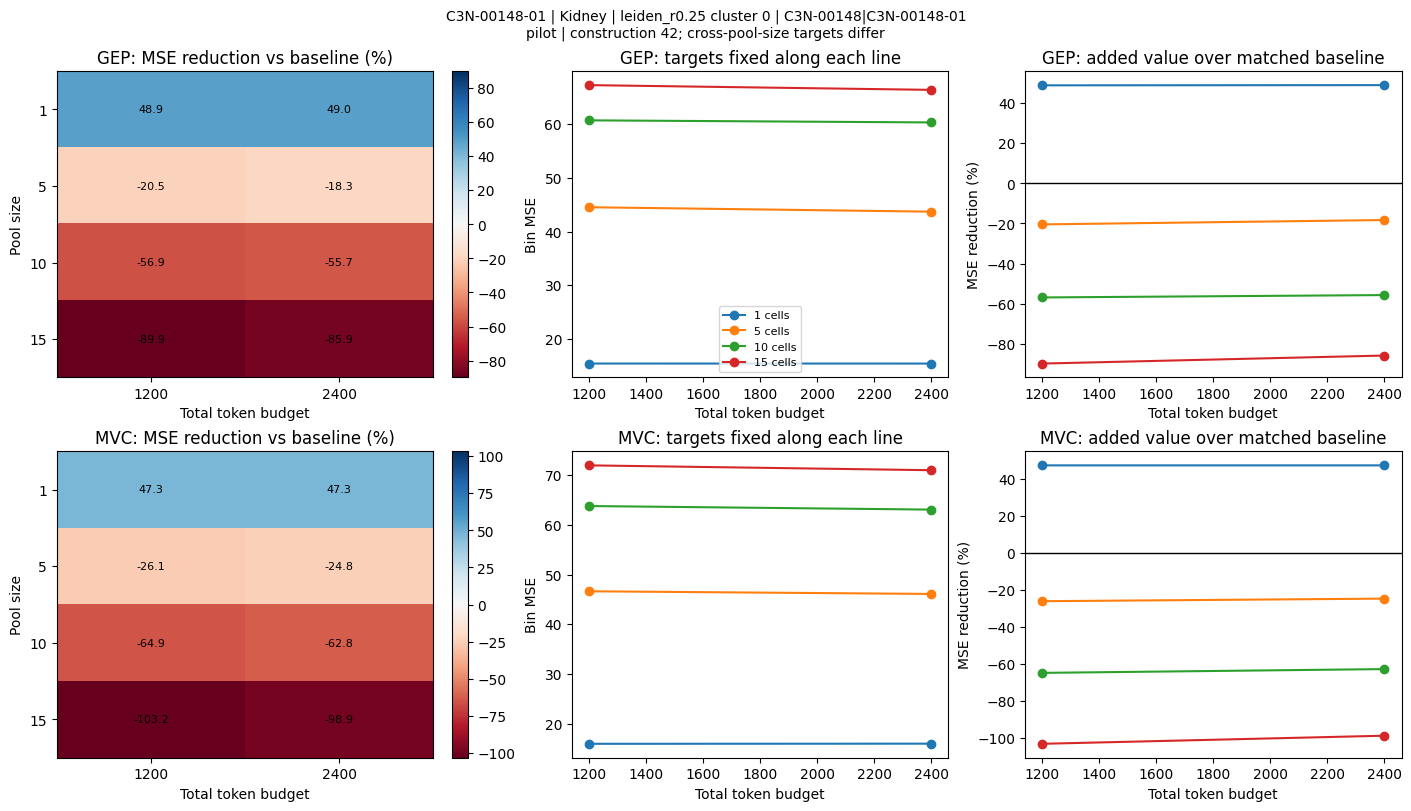

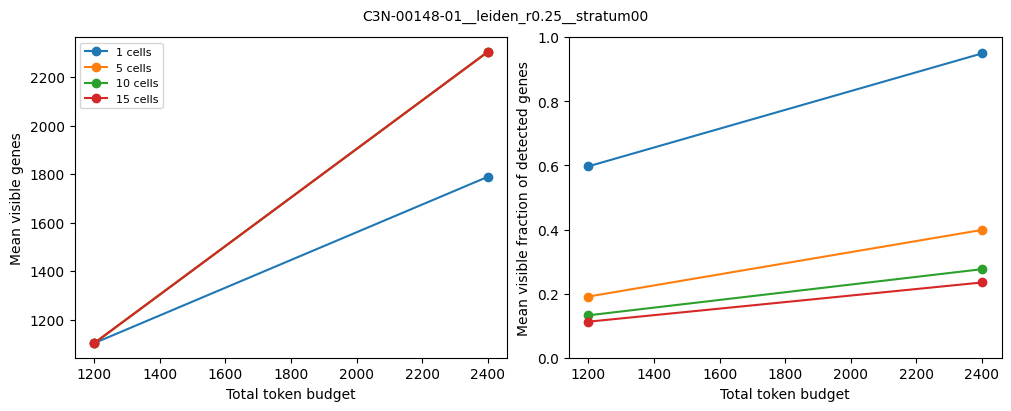

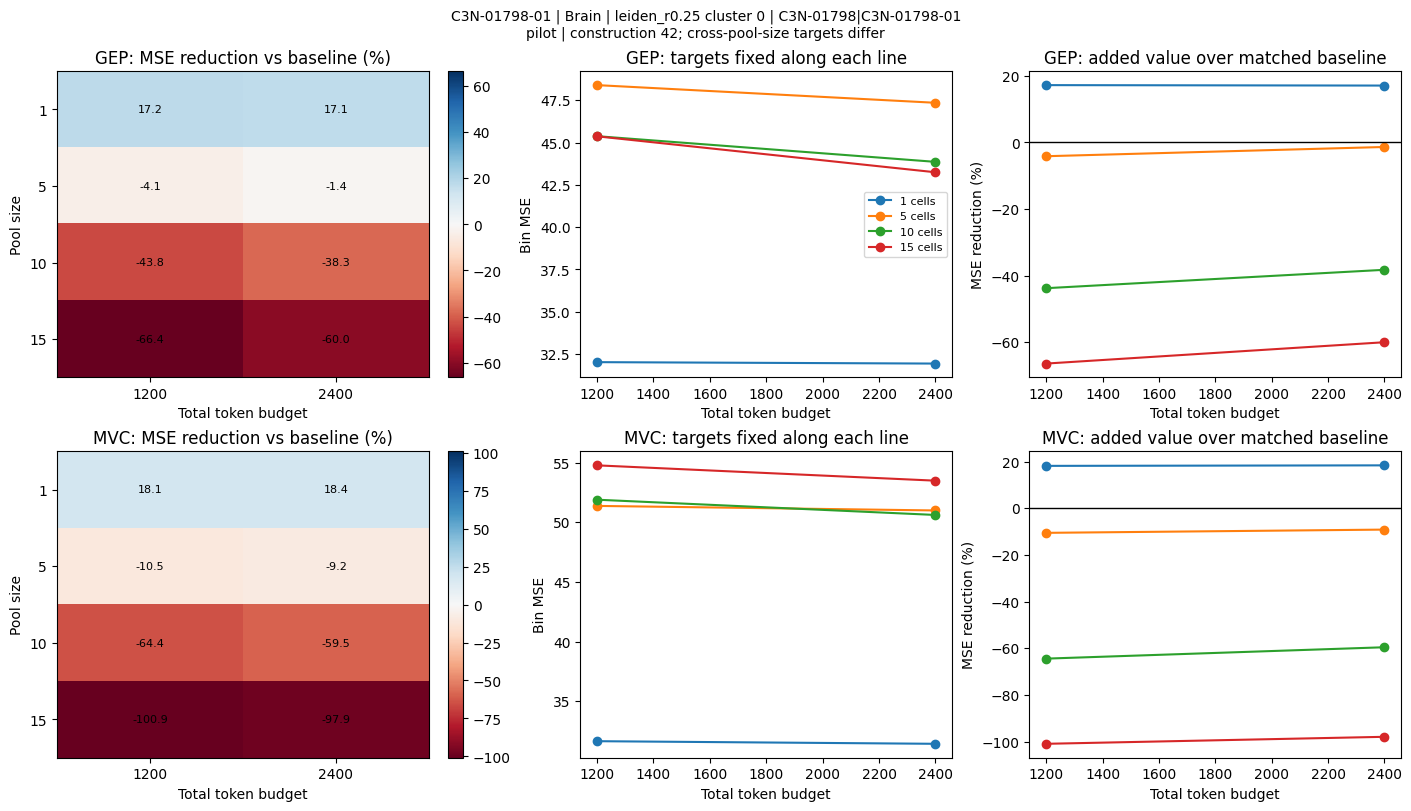

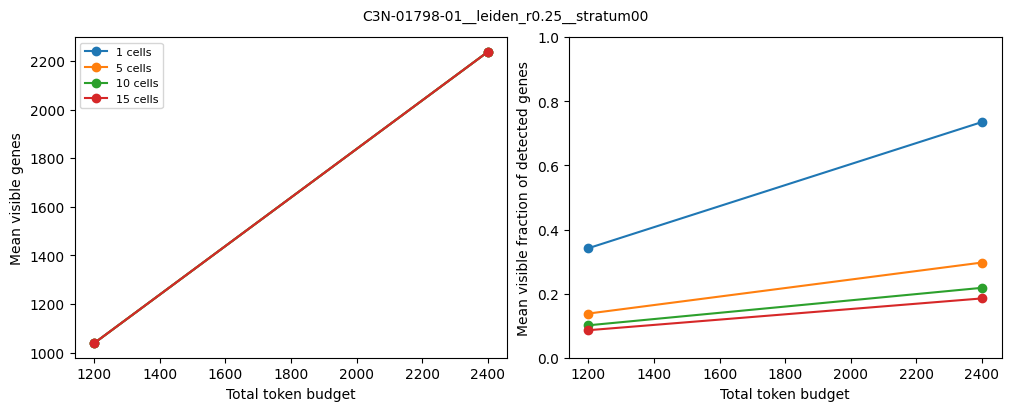

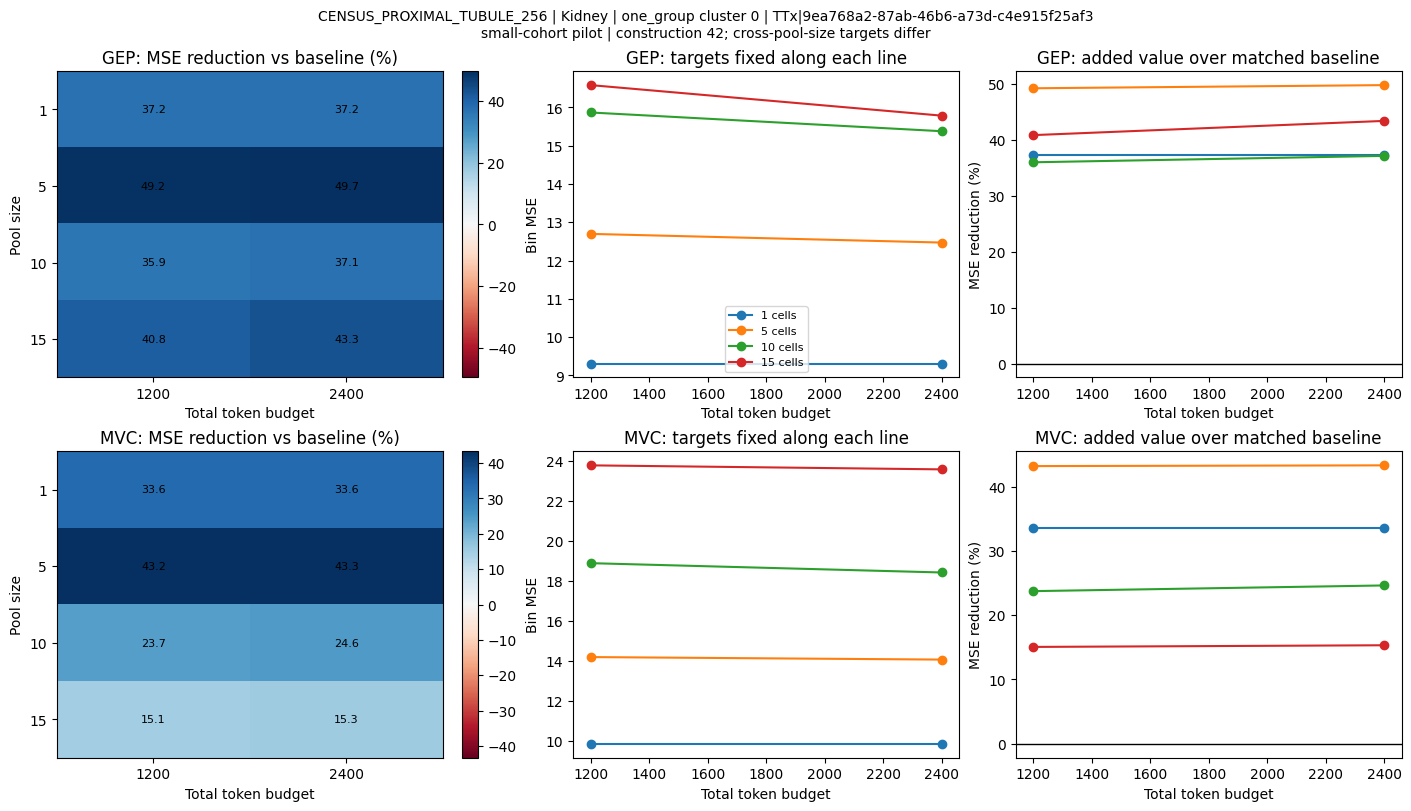

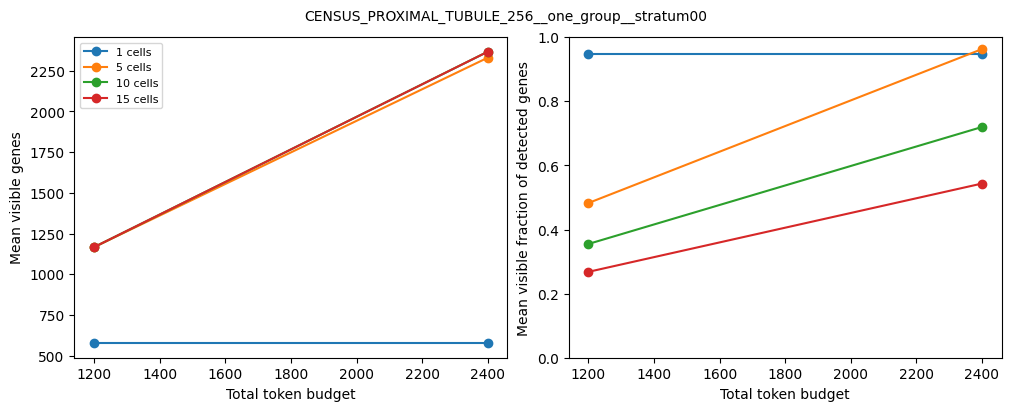

Saved: /home/akash1/scgpt-cna/aggregation_context/results/20261123T212849877781Z_pilot


,unit_id,pool_size,context_budget,count_group,method,construction_seed,n_families,mean_MSE,mean_MAE,baseline_MSE,...,diagnosis,label_column,cluster,pooling_block,n_source_cells,n_reference_families,n_evaluation_families,evidence_status,gain_low,gain_high
24,C3N-00148-01__leiden_r0.25__stratum00,1,1200,all,GEP,42,4,15.434,3.178,30.227,...,"Renal cell carcinoma, NOS",leiden_r0.25,0,C3N-00148|C3N-00148-01,3297,8,4,pilot,10.860,20.794
26,C3N-00148-01__leiden_r0.25__stratum00,1,1200,all,MVC,42,4,15.936,3.223,30.227,...,"Renal cell carcinoma, NOS",leiden_r0.25,0,C3N-00148|C3N-00148-01,3297,8,4,pilot,10.745,19.203
29,C3N-00148-01__leiden_r0.25__stratum00,1,1200,all,gene_mean_plus_offset,42,4,30.227,4.442,30.227,...,"Renal cell carcinoma, NOS",leiden_r0.25,0,C3N-00148|C3N-00148-01,3297,8,4,pilot,0.000,0.000
56,C3N-00148-01__leiden_r0.25__stratum00,1,2400,all,GEP,42,4,15.428,3.163,30.279,...,"Renal cell carcinoma, NOS",leiden_r0.25,0,C3N-00148|C3N-00148-01,3297,8,4,pilot,10.416,20.436
58,C3N-00148-01__leiden_r0.25__stratum00,1,2400,all,MVC,42,4,15.963,3.215,30.279,...,"Renal cell carcinoma, NOS",leiden_r0.25,0,C3N-00148|C3N-00148-01,3297,8,4,pilot,10.812,19.274
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
730,CENSUS_PROXIMAL_TUBULE_256__one_group__stratum00,15,1200,all,MVC,42,3,23.790,3.742,28.011,...,Census-annotated proximal-tubule cohort,one_group,0,TTx|9ea768a2-87ab-46b6-a73d-c4e915f25af3,118,3,3,small-cohort pilot,-15.035,19.836
733,CENSUS_PROXIMAL_TUBULE_256__one_group__stratum00,15,1200,all,gene_mean_plus_offset,42,3,28.011,3.493,28.011,...,Census-annotated proximal-tubule cohort,one_group,0,TTx|9ea768a2-87ab-46b6-a73d-c4e915f25af3,118,3,3,small-cohort pilot,0.000,0.000
760,CENSUS_PROXIMAL_TUBULE_256__one_group__stratum00,15,2400,all,GEP,42,3,15.787,2.641,27.858,...,Census-annotated proximal-tubule cohort,one_group,0,TTx|9ea768a2-87ab-46b6-a73d-c4e915f25af3,118,3,3,small-cohort pilot,0.636,21.080
762,CENSUS_PROXIMAL_TUBULE_256__one_group__stratum00,15,2400,all,MVC,42,3,23.589,3.739,27.858,...,Census-annotated proximal-tubule cohort,one_group,0,TTx|9ea768a2-87ab-46b6-a73d-c4e915f25af3,118,3,3,small-cohort pilot,-13.698,18.752


Primary context effects: positive gain means larger context lowered MSE on the same target values.


,unit_id,pool_size,method,construction_seed,gain_from_long_context
0,C3N-00148-01__leiden_r0.25__stratum00,1,GEP,42,0.006
1,C3N-00148-01__leiden_r0.25__stratum00,1,MVC,42,-0.028
2,C3N-00148-01__leiden_r0.25__stratum00,5,GEP,42,0.824
3,C3N-00148-01__leiden_r0.25__stratum00,5,MVC,42,0.533
4,C3N-00148-01__leiden_r0.25__stratum00,10,GEP,42,0.387
5,C3N-00148-01__leiden_r0.25__stratum00,10,MVC,42,0.718
6,C3N-00148-01__leiden_r0.25__stratum00,15,GEP,42,0.884
7,C3N-00148-01__leiden_r0.25__stratum00,15,MVC,42,0.977
8,C3N-01798-01__leiden_r0.25__stratum00,1,GEP,42,0.084
9,C3N-01798-01__leiden_r0.25__stratum00,1,MVC,42,0.219


In [ ]:
# 8 — Score, bootstrap paired family gains within units, and make report figures. Model-free.
import matplotlib.pyplot as plt
assert (RUN_DIR/'inference_complete.json').is_file()
methods=['GEP','MVC','GEP_shuffled','MVC_shuffled','gene_mean_plus_offset','gene_mean','visible_mean','reference_constant']
score_rows=[];input_frames=[]
for u in units.to_dict('records'):
    d=RUN_DIR/u['unit_id']
    for construction in POOL_SEEDS:
        for mask in MASK_SEEDS:
            q=pd.read_csv(d/f'predictions_seed{construction}_mask{mask}.csv.gz')
            assert not q.duplicated(['pool_row','gene_token','context_budget']).any()
            input_frames.append(pd.read_csv(d/f'inference_inputs_seed{construction}_mask{mask}.csv'))
            for (size,family,length),part in q.groupby(['pool_size','family_id','context_budget'],sort=False):
                # Original anchor UMI groups stay fixed across size; pooled counts exported separately.
                groups=group_umi(part.anchor_umi.to_numpy())
                for group in ['all','1 UMI','2–4 UMIs','5+ UMIs']:
                    s=part if group=='all' else part.loc[groups==group]
                    if s.empty:continue
                    y=s.target_bin.to_numpy(float)
                    for method in methods:
                        p=s[method].to_numpy(float);e=p-y
                        score_rows.append(dict(unit_id=u['unit_id'],construction_seed=construction,family_id=family,pool_size=size,
                            context_budget=length,count_group=group,mask_seed=mask,method=method,n_queries=len(s),MSE=np.square(e).mean(),
                            MAE=abs(e).mean(),signed_error=e.mean(),target_variance=y.var(),prediction_variance=p.var(),
                            reference_support_fraction=float(s.reference_support.gt(0).mean())))
scores=pd.DataFrame(score_rows)
cond=['unit_id','pool_size','context_budget','count_group','method']
family=scores.groupby(cond+['construction_seed','family_id'],as_index=False)[['MSE','MAE','signed_error','target_variance','prediction_variance','reference_support_fraction']].mean()
join=[x for x in cond if x!='method']+['construction_seed','family_id']
b=family.loc[family.method.eq('gene_mean_plus_offset'),join+['MSE']].rename(columns={'MSE':'baseline_MSE'})
family=family.merge(b,on=join,validate='many_to_one');family['gain']=family.baseline_MSE-family.MSE
# Repeated constructions are summarized separately: never count reused source cells as new independent families.
summary=family.groupby(cond+['construction_seed'],as_index=False).agg(n_families=('family_id','nunique'),mean_MSE=('MSE','mean'),mean_MAE=('MAE','mean'),
    baseline_MSE=('baseline_MSE','mean'),mean_gain=('gain','mean'),median_gain=('gain','median'),
    mean_target_variance=('target_variance','mean'),mean_signed_error=('signed_error','mean'),
    fraction_families_model_wins=('gain',lambda x:float(x.gt(0).mean())))
summary['percent_MSE_reduction']=100*summary.mean_gain/summary.baseline_MSE
summary['MSE_over_target_variance']=summary.mean_MSE/summary.mean_target_variance.where(summary.mean_target_variance.gt(1e-12))
summary=summary.merge(units,on='unit_id',validate='many_to_one')
# Paired differences between smallest and largest context on the exact same pooled targets/query identities.
keys=['unit_id','pool_size','count_group','method','construction_seed','family_id']
lo=family.loc[family.context_budget.eq(min(LENGTHS)),keys+['MSE']].rename(columns={'MSE':'short_MSE'})
hi=family.loc[family.context_budget.eq(max(LENGTHS)),keys+['MSE']].rename(columns={'MSE':'long_MSE'})
paired=lo.merge(hi,on=keys,validate='one_to_one');paired['gain_from_long_context']=paired.short_MSE-paired.long_MSE
# Conditional within-unit intervals, using families as the resampling unit; masks already averaged.
ci=[]
for key,s in family.groupby(cond+['construction_seed'],sort=False):
    values=s.gain.to_numpy();rng=np.random.default_rng(rng_seed('ci',*key))
    draws=values[rng.integers(0,len(values),size=(BOOTSTRAPS,len(values)))].mean(axis=1)
    low,high=np.quantile(draws,[.025,.975]);ci.append(dict(zip(cond+['construction_seed'],key),gain_low=low,gain_high=high))
summary=summary.merge(pd.DataFrame(ci),on=cond+['construction_seed'],validate='one_to_one')
inputs=pd.concat(input_frames,ignore_index=True)
for name,frame in [('scores_by_pool_mask',scores),('scores_by_family',family),('condition_summary',summary),('paired_context_gains',paired),('inference_inputs',inputs)]:
    frame.to_csv(RUN_DIR/f'{name}.csv',index=False)
FIG=RUN_DIR/'figures';FIG.mkdir(exist_ok=True)

def save_fig(fig,name):
    fig.savefig(FIG/f'{name}.png',dpi=220,bbox_inches='tight');fig.savefig(FIG/f'{name}.pdf',bbox_inches='tight')
    plt.show();plt.close(fig)

for u in units.to_dict('records'):
    for construction in POOL_SEEDS:
        s=summary.loc[summary.unit_id.eq(u['unit_id'])&summary.construction_seed.eq(construction)&summary.count_group.eq('all')]
        fig,axes=plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
        for r,head in enumerate(['GEP','MVC']):
            p=s.loc[s.method.eq(head)].pivot(index='pool_size',columns='context_budget',values='percent_MSE_reduction').reindex(index=POOL_SIZES,columns=LENGTHS)
            lim=max(1,float(np.nanmax(abs(p.to_numpy()))))
            im=axes[r,0].imshow(p,cmap='RdBu',vmin=-lim,vmax=lim,aspect='auto')
            axes[r,0].set(xticks=range(len(LENGTHS)),xticklabels=LENGTHS,yticks=range(len(POOL_SIZES)),yticklabels=POOL_SIZES,
                xlabel='Total token budget',ylabel='Pool size',title=f'{head}: MSE reduction vs baseline (%)')
            for i in range(len(p)):
                for j in range(len(p.columns)):axes[r,0].text(j,i,f'{p.iloc[i,j]:.1f}',ha='center',va='center',fontsize=8)
            fig.colorbar(im,ax=axes[r,0])
            for size in POOL_SIZES:
                t=s.loc[s.method.eq(head)&s.pool_size.eq(size)].sort_values('context_budget')
                axes[r,1].plot(t.context_budget,t.mean_MSE,'o-',label=f'{size} cells')
                axes[r,2].plot(t.context_budget,t.percent_MSE_reduction,'o-',label=f'{size} cells')
            axes[r,1].set(title=f'{head}: targets fixed along each line',xlabel='Total token budget',ylabel='Bin MSE')
            axes[r,2].axhline(0,color='black',lw=1);axes[r,2].set(title=f'{head}: added value over matched baseline',xlabel='Total token budget',ylabel='MSE reduction (%)')
        axes[0,1].legend(fontsize=8)
        fig.suptitle(f"{u['sample_id']} | {u['tissue']} | {u['label_column']} cluster {u['cluster']} | {u['pooling_block']}\n{u['evidence_status']} | construction {construction}; cross-pool-size targets differ",fontsize=10)
        save_fig(fig,f"performance_{u['unit_id']}_seed{construction}")
        z=inputs.loc[inputs.unit_id.eq(u['unit_id'])&inputs.construction_seed.eq(construction)]
        # masks -> family -> unit for equal-weight coverage curves.
        z=z.groupby(['family_id','pool_size','context_budget'],as_index=False)[['n_visible','visible_fraction']].mean()
        z=z.groupby(['pool_size','context_budget'],as_index=False)[['n_visible','visible_fraction']].mean()
        fig,axes=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
        for size in POOL_SIZES:
            t=z.loc[z.pool_size.eq(size)].sort_values('context_budget')
            axes[0].plot(t.context_budget,t.n_visible,'o-',label=f'{size} cells');axes[1].plot(t.context_budget,t.visible_fraction,'o-')
        axes[0].legend(fontsize=8);axes[0].set(xlabel='Total token budget',ylabel='Mean visible genes')
        axes[1].set(xlabel='Total token budget',ylabel='Mean visible fraction of detected genes',ylim=(0,1))
        fig.suptitle(u['unit_id'],fontsize=10);save_fig(fig,f"coverage_{u['unit_id']}_seed{construction}")
print('Saved:',RUN_DIR)
display(summary.loc[summary.count_group.eq('all')&summary.method.isin(['GEP','MVC','gene_mean_plus_offset'])].round(3))
print('Primary context effects: positive gain means larger context lowered MSE on the same target values.')
display(paired.loc[paired.count_group.eq('all')&paired.method.isin(['GEP','MVC'])].groupby(['unit_id','pool_size','method','construction_seed'],as_index=False).gain_from_long_context.mean().round(3))

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# RUN_DIR should still point to this aggregation experiment.
# If reopening, run the notebook's reload cell 9 first.
run = Path(RUN_DIR)

# 1. How many genes have positive counts in each evaluated aggregate?
profiles = pd.read_csv(run / "pool_profiles.csv")
evaluated = profiles.loc[profiles["partition"].eq("evaluation")].copy()

gene_counts = evaluated.groupby(
    ["unit_id", "construction_seed", "pool_size"],
    as_index=False,
).agg(
    n_pools=("family_id", "nunique"),
    min_detected_genes=("detected_model_genes", "min"),
    median_detected_genes=("detected_model_genes", "median"),
    max_detected_genes=("detected_model_genes", "max"),
    median_total_counts=("total_counts", "median"),
)

print("Positive-count model genes per evaluated pool:")
display(gene_counts.round(1))

# 2. How much context was ACTUALLY supplied?
inputs = pd.read_csv(run / "inference_inputs.csv")

# Average masks within each family first.
per_family = inputs.groupby(
    [
        "unit_id", "construction_seed", "pool_size",
        "context_budget", "family_id",
    ],
    as_index=False,
).agg(
    n_visible=("n_visible", "mean"),
    n_queries=("n_queries", "mean"),
    visible_fraction=("visible_fraction", "mean"),
    all_available_context_used=("saturated", "mean"),
)

actual_context = per_family.groupby(
    ["unit_id", "construction_seed", "pool_size", "context_budget"],
    as_index=False,
).agg(
    n_families=("family_id", "nunique"),
    mean_visible_genes=("n_visible", "mean"),
    mean_query_genes=("n_queries", "mean"),
    mean_visible_fraction=("visible_fraction", "mean"),
    fraction_fully_covered=("all_available_context_used", "mean"),
)

print("Actual visible context at each requested budget:")
display(actual_context.round(3))